<a href="https://colab.research.google.com/github/SNIGDHA-ms24043/IDC-PROJECT--Music-Genre-Classification/blob/main/Music_Genre_IDC_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("let's goooo")
print("music genre classification ")
print("features ")

let's goooo
music genre classification 
features 


In [ ]:
# Snigdha
'''
Roadmap
1) create table => Use audio features such as MFCC,chroma, spectral centroid, tempo and energy.=> done already
2) Start with extracted-feature CSV if audio processing is too hard.
Advanced one can use Librosa to extract features from .wav files. => Librosa is a Python library specifically designed for analyzing audio and music.
.wav is an audio file format.
3)EDA: compare tempo, spectral features and MFCC patterns across genres=> done
4)Classification: KNN, SVM, RandomForest, Logistic Regression.Feature scaling is important for KNN/SVM.Optional deep learning: CNN on spectrogram images.
5)Model comparison and confusion matrix.
Short audio/AI reflection: which genres are confused and why?
6)Metrics: accuracy, macro F1, confusion matrix.
Check class balance across genres.
Extension: build a simple song-similarity recommender using
cosine similarity.

In [3]:
# Snigdha
'''importing files and show number of columns and rows
'''
import pandas as pd
df=pd.read_excel("/content/features_3_sec.csv.xlsx")
#f-string (formatted string).=>It allows you to put Python variables/calculations directly inside a piece of text using {}
print(f"Loaded rows={df.shape[0]}, columns={df.shape[1]}")

Loaded rows=998, columns=60


In [ ]:
# Snigdha
'''
Data description
1) filename= the genre of a music
2) length = duration of the song (seconds)
3) chroma_stft=Average chroma feature calculated using STFT *
4) rms=Root Mean Square energy *
5) spectral_centroid=Center of the frequency spectrum ["center of mass" of the frequencies]
6) spectral_bandwidth=Spread of frequencies around the spectral centroid
7) rolloff=Frequency below which a chosen percentage of total spectral energy lies
8) zero_crossing_rate=Rate at which the waveform crosses zero
9) harmony=Harmonic component of the audio
10)perceptr=Perceptual/tonal audio feature in this dataset *
11)tempo=Estimated tempo=> estimated speed of the music, generally expressed in BPM: beats per minute.
12)mfcc [1-20]=20 Mel-Frequency Cepstral Coefficients=> they provide information about the spectral shape/timbre of sound, using a frequency representation related to human auditory perception.
[compact numerical description of characteristics of the sound's spectrum]
13)label=Genre/class assigned to the song

Notes

3)Chroma looks at the distribution of musical pitch classes.
STFT = Short-Time Fourier Transform.
It allows us to examine the frequency content of the music over short periods of time.
chroma_stft tells us about the distribution of musical pitch/harmonic content over time.

4) as a measure related to the energy/intensity of the audio signal.

10)The name perceptr isn't one of the standard Librosa feature names in the same straightforward way as tempo, rms, spectral_centroid, or mfcc.
It may represent a perceptual/tonal feature calculated by the dataset's feature-extraction pipeline.

In [4]:
#gurleen
# EDA Notebook with genre comparison plots(minimum deliverables)

# combined dataframe
all_sheets = pd.read_excel("/content/features_3_sec.csv.xlsx", sheet_name=None)
#sheet_name=None: Tells Pandas to read every single worksheet tab in the Excel file, instead of stopping after the first tab.
'''Output: Creates a Python dictionary where:
Keys = Tab names (e.g., 'CLASSICAL', 'ROCK', 'POP').
Values = Individual DataFrames containing the rows for that specific genre tab.'''

df = pd.concat(all_sheets.values(), ignore_index=True)
#Vertical Stacking:Because every sheet has the same column headers,Pandas stacks the sheets vertically on top of each other.
#with ignore_index=True, you ensure both label indexing (.loc) and positional indexing (.iloc) behave predictably.(assigns clean Index 0 to 5992)
print(f"Combined DataFrame shape: {df.shape}")

print("\nSong / Slice counts per genre:")
print(df["label"].value_counts())


Combined DataFrame shape: (5993, 60)

Song / Slice counts per genre:
label
pop          1000
jazz         1000
disco         999
classical     998
rock          998
hiphop        998
Name: count, dtype: int64


In [ ]:
#gurleen
#data quality check
display(df.describe())
#Compute summary statistics (count, mean, std, min, max, quartiles) for numeric columns
print("dtypes")
display(df.dtypes)
#Inspect data types (e.g., float64, int64, object/string) across all columns
print("isna")
display(df.isna().sum())
#Check for number of missing or null (NaN) values column-by-column and sum them.

,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,...,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
count,5993.0,5993.000000,5993.000000,5993.000000,5.993000e+03,5993.000000,5.993000e+03,5993.000000,5.993000e+03,5993.000000,...,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000,5993.000000
mean,66149.0,0.369765,0.085313,0.128493,3.138759e-03,2265.230236,4.501238e+05,2305.666850,1.157067e+05,4729.658658,...,1.147663,51.496599,-2.745784,53.746498,0.696740,55.751498,-1.806700,59.343750,-0.640064,62.662091
std,0.0,0.092304,0.008304,0.074561,4.253689e-03,800.434954,4.692345e+05,612.913004,1.023451e+05,1809.642137,...,5.593858,38.789302,5.686764,39.518274,5.231412,41.809001,5.266784,47.382750,5.293887,52.241778
min,66149.0,0.107108,0.038064,0.000953,4.379535e-08,472.741636,8.118813e+02,499.162910,1.653263e+03,658.336276,...,-26.850016,3.070262,-27.809795,1.624544,-20.733809,3.437439,-27.448456,3.065302,-35.640659,1.429122
25%,66149.0,0.299573,0.080289,0.069345,5.016397e-04,1643.004276,1.150352e+05,1863.473852,4.868666e+04,3330.772423,...,-2.448044,29.183075,-6.429787,29.949141,-2.635681,30.325510,-5.174462,31.134136,-3.789416,31.285770
50%,66149.0,0.381032,0.084971,0.121310,1.574680e-03,2282.579370,2.931697e+05,2311.503052,8.873703e+04,4803.974797,...,0.909661,41.604786,-2.846961,43.233727,0.431402,43.638138,-2.048507,45.675880,-0.895388,47.818382
75%,66149.0,0.439004,0.090665,0.182003,3.873321e-03,2829.708631,6.233330e+05,2760.571284,1.516846e+05,5992.276330,...,4.396758,60.209942,0.577235,63.435772,3.622621,67.347115,1.164105,71.660454,2.271236,75.617569
max,66149.0,0.738563,0.114378,0.442567,3.261522e-02,4952.034726,4.794119e+06,3708.147554,1.235143e+06,9487.446477,...,39.144405,683.932556,34.048843,529.363342,36.970322,629.729797,31.365425,1143.230591,34.212101,910.473206


dtypes


,0
filename,object
length,int64
chroma_stft_mean,float64
chroma_stft_var,float64
rms_mean,float64
rms_var,float64
spectral_centroid_mean,float64
spectral_centroid_var,float64
spectral_bandwidth_mean,float64
spectral_bandwidth_var,float64


isna


,0
filename,0
length,0
chroma_stft_mean,0
chroma_stft_var,0
rms_mean,0
rms_var,0
spectral_centroid_mean,0
spectral_centroid_var,0
spectral_bandwidth_mean,0
spectral_bandwidth_var,0


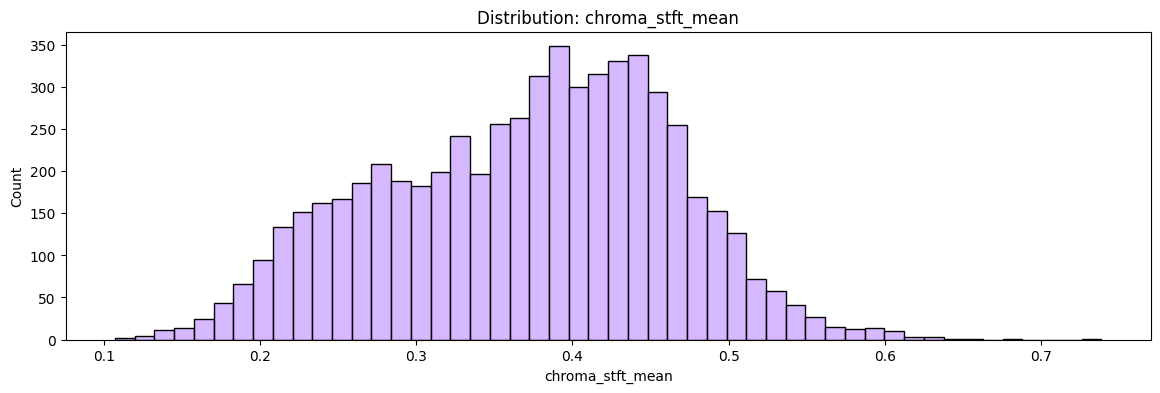

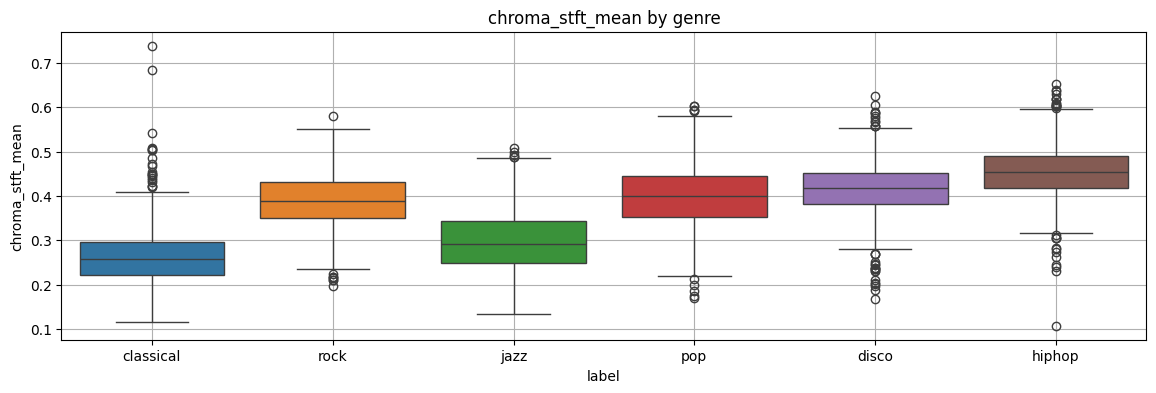

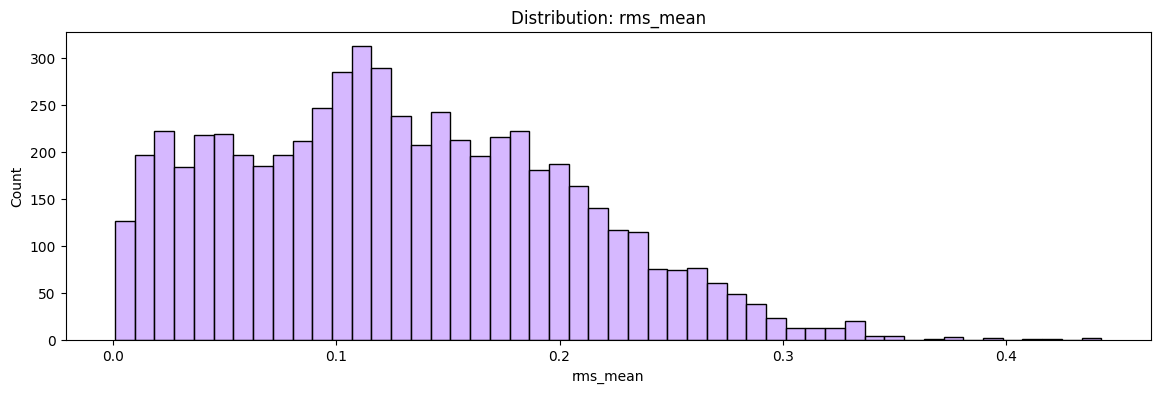

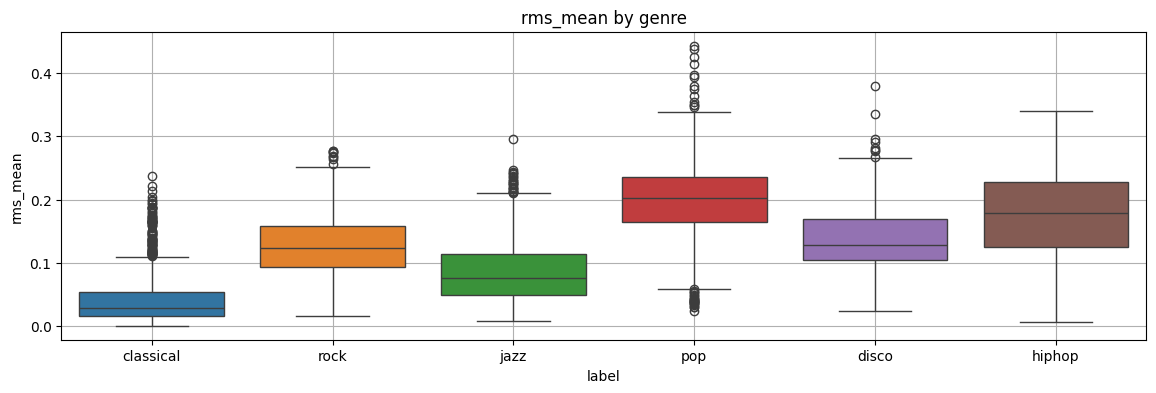

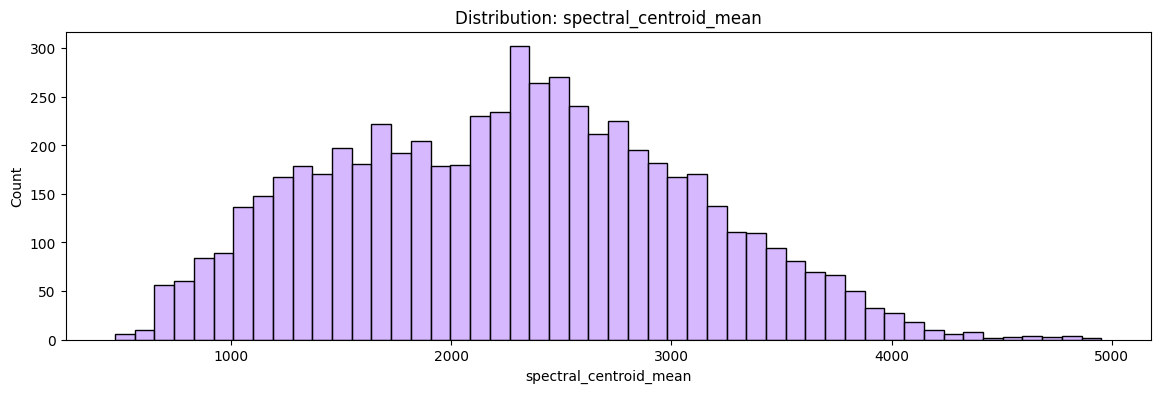

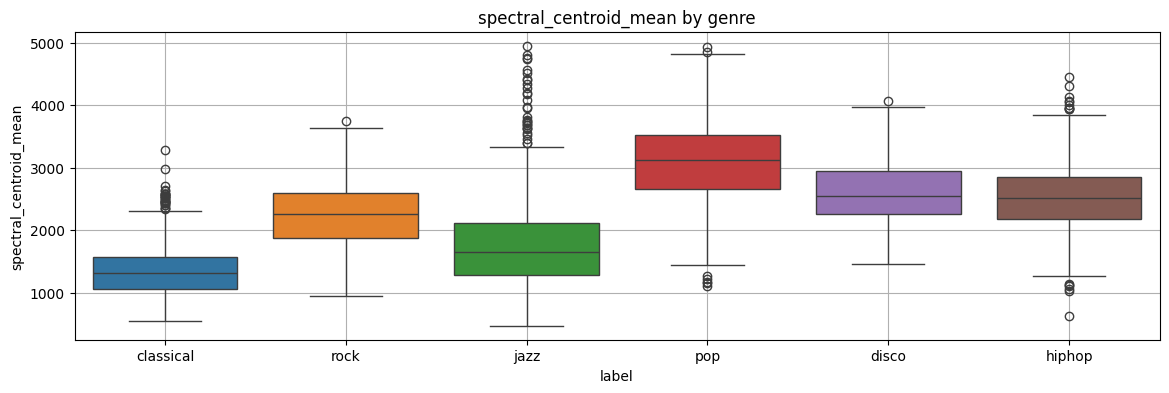

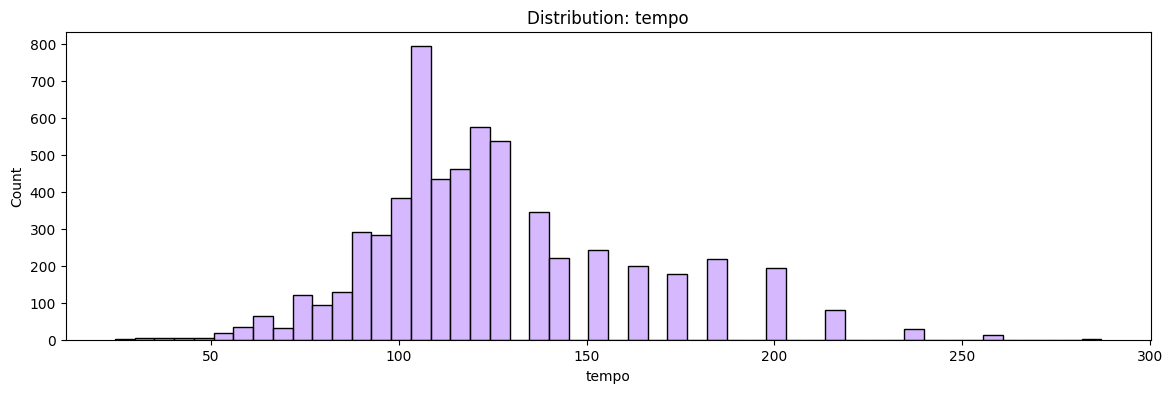

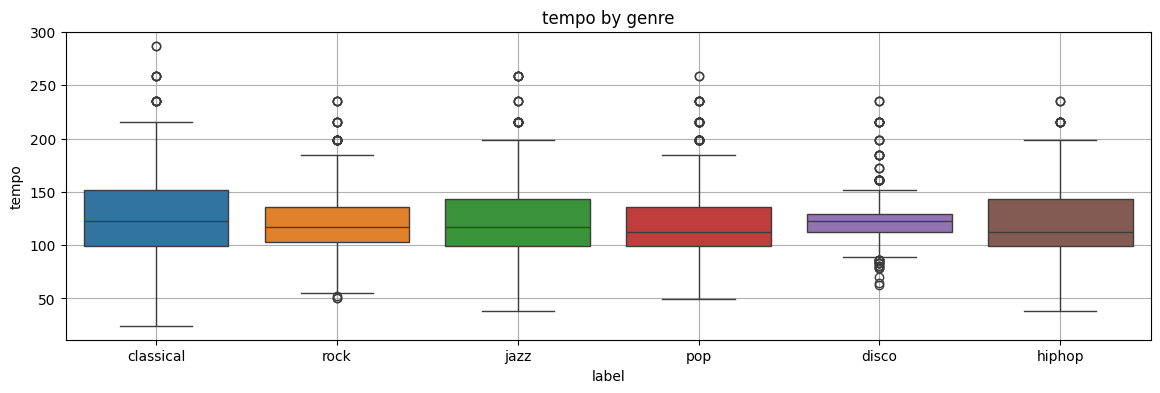

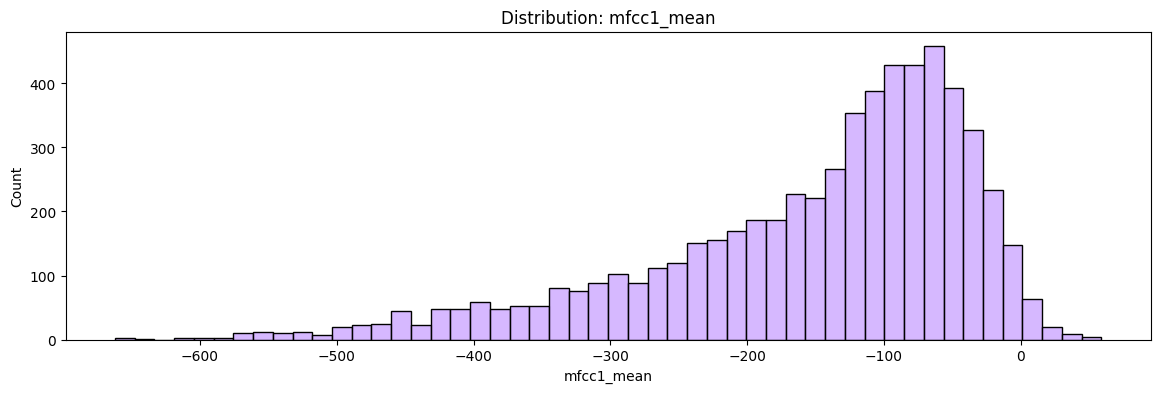

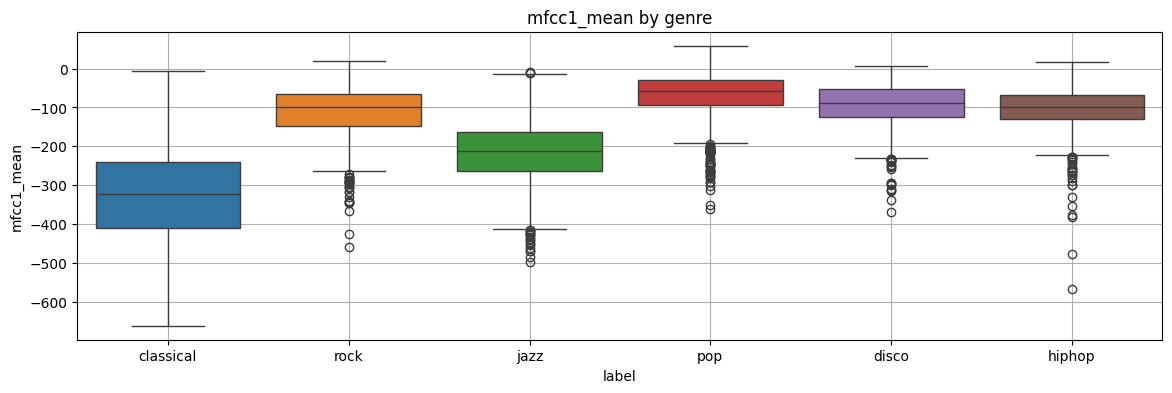

In [ ]:
#gurleen
#distribution analysis using histogram and box plot
import matplotlib.pyplot as plt # Handles the figure dimensions (figsize), titles, axis labels, and rendering (plt.show()).
import pandas as pd # Manages tabular datasets (DataFrames), supporting data loading, missing value checks, and feature selections.
import seaborn as sns #Produces high-level statistical plots (such as histograms, box plots, count plots, and heatmaps) with built-in color palettes.

numeric_cols = ["chroma_stft_mean","rms_mean","spectral_centroid_mean","tempo","mfcc1_mean"]
#Define key numerical audio metrics to inspect for skewness, spread, and genre separability.
#Loop through each audio feature to generate distribution and genre-comparison plots
for col in numeric_cols:
    plt.figure(figsize=(14, 4))
    sns.histplot(data=df, x=col, bins=50, color="#C9A0FF")#Plot overall feature distribution (histogram)
    plt.title(f"Distribution: {col}")
    plt.show()
    plt.figure(figsize=(14, 4))
    sns.boxplot(data=df, y=col, x="label", hue="label")#Plot feature breakdown across music genres (box plot)
    plt.title(f"{col} by genre")
    plt.grid()
    plt.show()


'Sub-sampling: A pairplot creates an NxN grid of scatter plots.Taking a random sample of 500 rows makes the plot render almost instantly while still showing clear distribution trends.\n   Random_state=42: Ensures reproducibility—you get the exact same random sample of songs every time you run the code.'

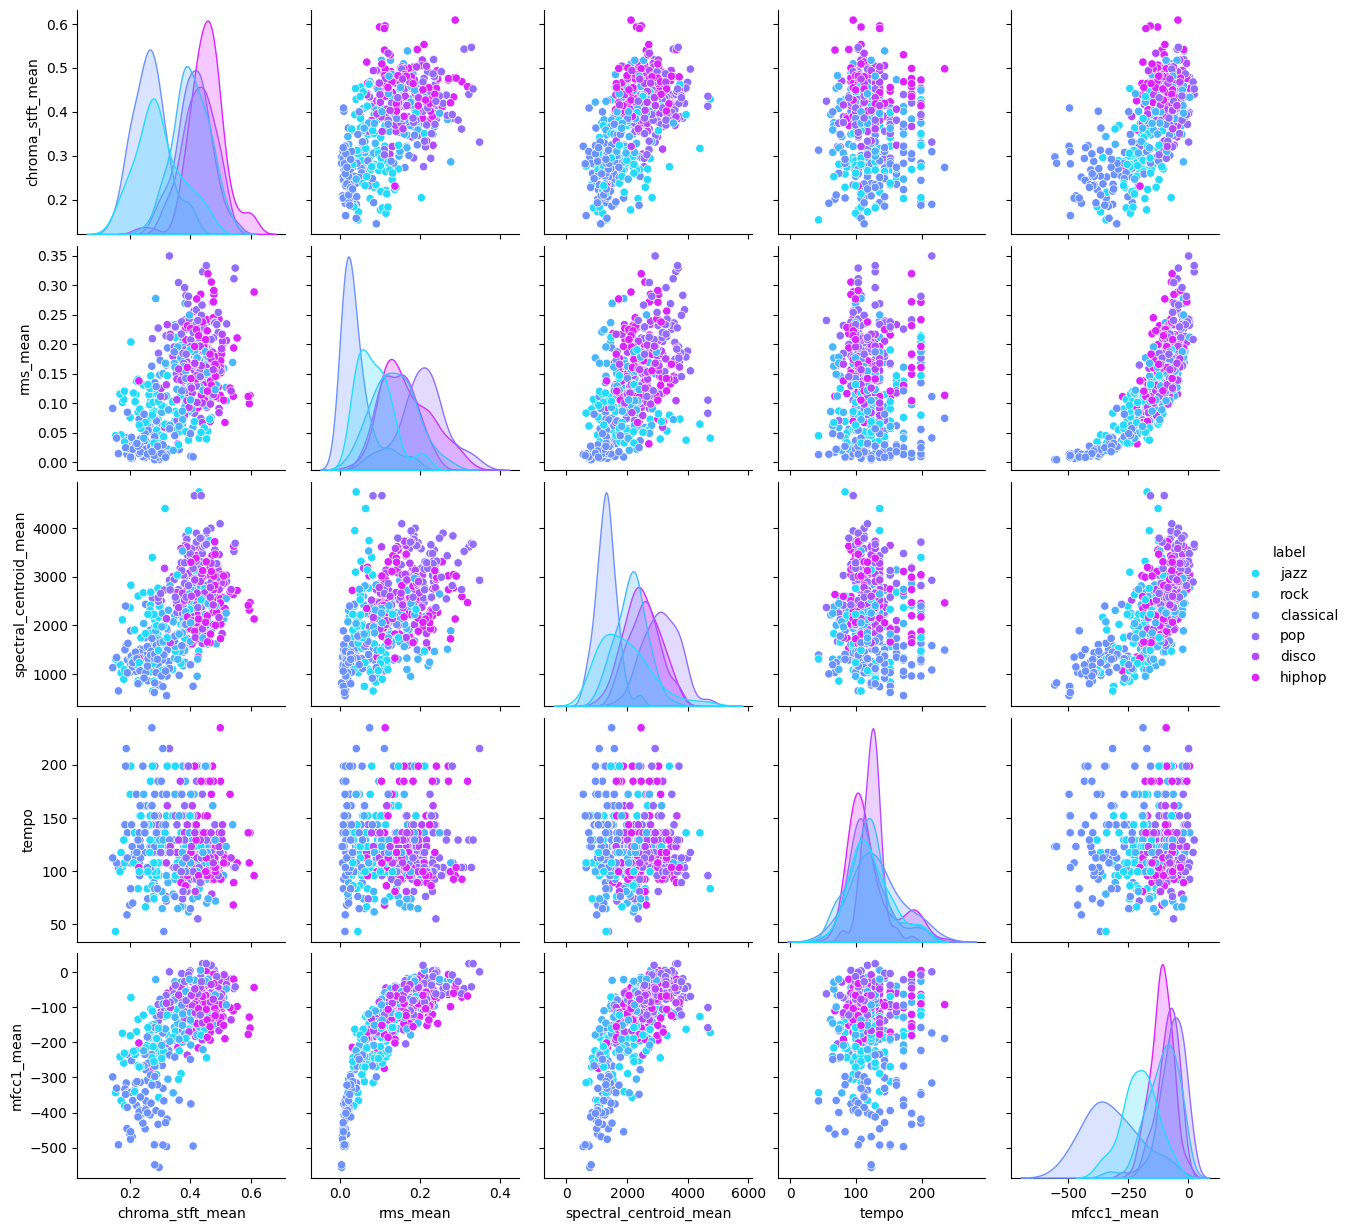

In [ ]:
#gurleen
#pairwise relationships
pair_cols = ["chroma_stft_mean","rms_mean","spectral_centroid_mean","tempo","mfcc1_mean","label"]
sns.pairplot(df[pair_cols].sample(min(500, len(df)), random_state=42), hue="label", palette="cool")
'''Sub-sampling: A pairplot creates an NxN grid of scatter plots.Taking a random sample of 500 rows makes the plot render almost instantly while still showing clear distribution trends.
   Random_state=42: Ensures reproducibility—you get the exact same random sample of songs every time you run the code.'''

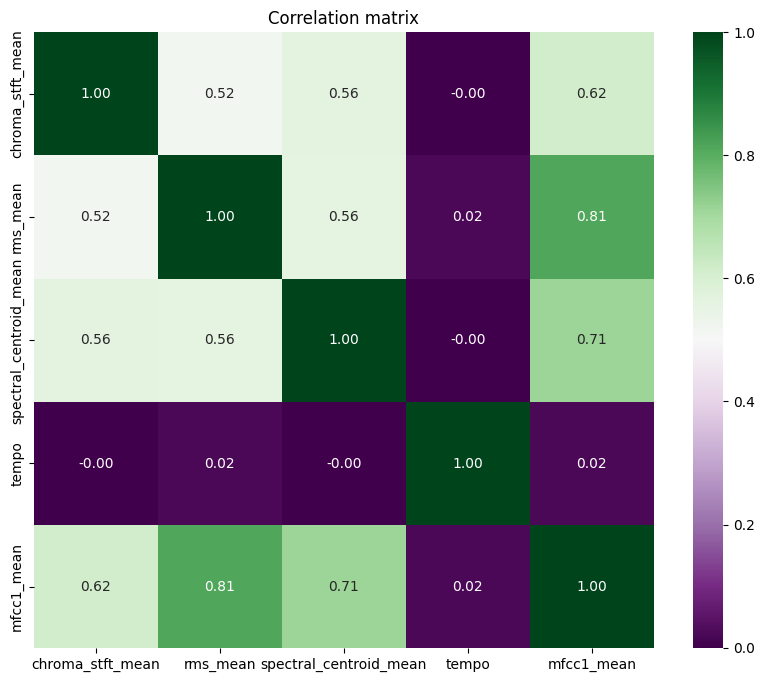

In [ ]:
#gurleen
corr_cols = ["chroma_stft_mean","rms_mean","spectral_centroid_mean","tempo","mfcc1_mean","label"]
corr_matrix = df[corr_cols].corr(numeric_only=True)
#Compute pairwise Pearson correlation coefficients (-1.0 to +1.0) for numerical columns for every pair of feature.
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='PRGn') # Display exact correlation values inside each cell and Format values to 2 decimal places.
plt.title("Correlation matrix")
plt.show()



In [ ]:
#Snigdha
#using Librosa to extract features from .wav files.
#First, install Librosa alongside soundfile (for loading audio formats) and matplotlib (for optional visualization)

'''
When you load an audio file using librosa.load, it automatically resamples the audio to a default sampling rate of 22,050 Hz and normalizes the amplitude.
It returns a 1D NumPy array representing the audio time-series signal (y) and the sample rate (sr)
'''
import librosa
import numpy as np

# Load audio file (supports WAV, MP3, FLAC, etc.)
audio_path = "/content/classical.00000.wav"
y, sr = librosa.load(audio_path, sr=None)  # sr=None preserves native sample rate
# Extract 13 MFCCs (commonly 13 to 40 are used)
mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
print("MFCCs shape:", mfccs.shape)  # Shape: (n_mfcc, number_of_frames)
chromagram = librosa.feature.chroma_stft(y=y, sr=sr)
print("Chroma shape:", chromagram.shape)  # Shape: (12, number_of_frames)
rms = librosa.feature.rms(y=y)
print("RMS shape:", rms.shape)  # Shape: (1, number_of_frames)
spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)
'''
Because audio files have different lengths, the extracted feature matrices will have varying numbers of time frames.
 To pass these into standard tabular machine learning models (like Random Forests, SVMs, or XGBoost), you should compress the
 time axis by calculating the mean and standard deviation across all frames
'''
# Function to aggregate features into a single row vector
def extract_global_features(y, sr):
    features = {}

    # Calculate raw features
    mfcc_feat = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    chroma_feat = librosa.feature.chroma_stft(y=y, sr=sr)
    rms_feat = librosa.feature.rms(y=y)

    # Aggregate over time windows using Mean and Std Dev
    features['mfcc_mean'] = np.mean(mfcc_feat, axis=1)
    features['mfcc_std'] = np.std(mfcc_feat, axis=1)

    features['chroma_mean'] = np.mean(chroma_feat, axis=1)
    features['rms_mean'] = np.mean(rms_feat)

    # Flatten everything into a single 1D array
    feature_vector = np.concatenate([
        features['mfcc_mean'],
        features['mfcc_std'],
        features['chroma_mean'],
        [features['rms_mean']]
    ])

    return feature_vector

# Extract a static feature row for one file
ML_ready_features = extract_global_features(y, sr)
print("Final feature vector size:", ML_ready_features.shape)

# 1. Load audio and extract spectral features
y, sr = librosa.load('/content/classical.00000.wav', sr=None)

spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)
# 2. Calculate the mean across time frames (axis=1)
# This squeezes the 2D array into a single average scalar value
mean_centroid = np.mean(spectral_centroids, axis=1)[0]


print(f"Mean Spectral Centroid: {mean_centroid:.2f} Hz")

MFCCs shape: (13, 1293)
Chroma shape: (12, 1293)
RMS shape: (1, 1293)
Final feature vector size: (39,)
Mean Spectral Centroid: 1505.36 Hz


In [ ]:
#Snigdha
#Extracting all imp audio features
import librosa
import numpy as np

# 1. Load the audio file
y, sr = librosa.load('/content/classical.00000.wav', sr=None)

# 2. Extract Features
spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)
# 2. Calculate the mean across time frames (axis=1)
# This squeezes the 2D array into a single average scalar value
mean_centroid = np.mean(spectral_centroids, axis=1)[0]


print(f"Mean Spectral Centroid: {mean_centroid:.2f} Hz")

# Tempo (returns a scalar or a 1D array depending on your librosa version)
tempo, _ = librosa.beat.beat_track(y=y, sr=sr)

# MFCCs (returns 2D array: [n_mfcc, time_frames])
mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

# Chroma (returns 2D array: [12_pitch_classes, time_frames])
chroma = librosa.feature.chroma_stft(y=y, sr=sr)

# Spectral Centroid (returns 2D array: [1, time_frames])
spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)

# Energy / RMS (returns 2D array: [1, time_frames])
energy = librosa.feature.rms(y=y)

# 3. Calculate Means (Averaging over time)

# Tempo is already an overall average metric, no axis needed
mean_tempo = tempo[0] if isinstance(tempo, np.ndarray) else tempo

# 2D features require axis=1 to average across the time columns
mean_mfccs = np.mean(mfccs, axis=1)              # Returns 13 values (one per coefficient)
mean_chroma = np.mean(chroma, axis=1)            # Returns 12 values (one per pitch)
mean_centroid = np.mean(spectral_centroids, axis=1)[0] # Returns a single scalar
mean_energy = np.mean(energy, axis=1)[0]         # Returns a single scalar


# 4. Print Results

print(f"Tempo: {mean_tempo:.2f} BPM")
print(f"Mean Centroid: {mean_centroid:.2f} Hz")
print(f"Mean Energy (RMS): {mean_energy:.4f}")
print(f"Mean MFCCs (first 3): {mean_mfccs[:3]}")
print(f"Mean Chroma (first 3): {mean_chroma[:3]}")


Mean Spectral Centroid: 1505.36 Hz
Tempo: 95.70 BPM
Mean Centroid: 1505.36 Hz
Mean Energy (RMS): 0.0362
Mean MFCCs (first 3): [-268.21857   135.68166   -34.056377]
Mean Chroma (first 3): [0.1244859  0.29797456 0.4111422 ]


In [2]:
#gurleen
import matplotlib.pyplot as plt# Figure creation, layout customization, and axis formatting.
import numpy as np# Multi-dimensional array handling and mathematical operations.
import pandas as pd# Data manipulation, cleaning, and DataFrame management.
import seaborn as sns# Advanced statistical plots (heatmaps, box plots, count plots).
from sklearn.ensemble import RandomForestClassifier# Ensemble tree-based classifier
from sklearn.linear_model import LogisticRegression# Linear model for multi-class classification


from sklearn.metrics import accuracy_score, classification_report, f1_score
# Calculates overall percentage of correct predictions.
#Generates Precision, Recall, F1-Score, and Support per class
# Measures harmonic mean of Precision and Recall
from sklearn.model_selection import train_test_split# Partitions data into training and testing subsets
from sklearn.neighbors import KNeighborsClassifier# Distance-based non-parametric classifier
from sklearn.preprocessing import LabelEncoder, StandardScaler# Converts categorical text labels into integer indices and Standardizes numerical features (zero mean, unit variance).
from sklearn.svm import SVC# Support Vector Classifier for complex decision boundaries
from sklearn.metrics import confusion_matrix# Builds actual vs. predicted classification error grid

In [ ]:
#gurleen + Snigdha (comments)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix
df=pd.read_excel("/content/features_3_sec.csv.xlsx")
# combined dataframe
all_sheets = pd.read_excel("/content/features_3_sec.csv.xlsx", sheet_name=None)
#sheet_name=None: Tells Pandas to read every single worksheet tab in the Excel file, instead of stopping after the first tab.
'''Output: Creates a Python dictionary where:
Keys = Tab names (e.g., 'CLASSICAL', 'ROCK', 'POP').
Values = Individual DataFrames containing the rows for that specific genre tab.'''

df = pd.concat(all_sheets.values(), ignore_index=True)
#Vertical Stacking:Because every sheet has the same column headers,Pandas stacks the sheets vertically on top of each other.
#with ignore_index=True, you ensure both label indexing (.loc) and positional indexing (.iloc) behave predictably.(assigns clean Index 0 to 5992)
print(f"Combined DataFrame shape: {df.shape}")
target_col = 'label'
ignore_cols = [target_col, 'filename', 'length']
#target_col is a variable that stores the name of the column to be predicted.
#label is the column containing the correct music genre for each song.

#filename is excluded because the song's filename is generally not a meaningful audio feature.
#length is excluded because it is not prediciting the genre here

# Automatically select ALL numerical feature columns
feature_cols = [c for c in df.columns if c not in ignore_cols]
#where c is a temporary variable representing one column name. This code goes through every column not in the exclusion list

X = df[feature_cols]
y = df[target_col]
#df[feature_cols] selects the feature columns and stores them in X.
#df[target_col] selects the label column and stores it in y.


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
'''
X_train	Features for training songs
X_test	Features for test songs
y_train	Correct genres for training songs
y_test	Correct genres for test songs
'''
#X: all the input features.
#y: all the correct genre labels.
#test_size=0.3: reserve 30% of the data for testing.
#stratify=y: preserve approximately the same proportion of each genre in the training and testing sets.
#random_state=42: make the random split reproducible, so you get the same split when rerunning the code on the same data.

scaler = StandardScaler()
#StandardScaler standardizes each feature using its mean and standard deviation

X_train_scaled = scaler.fit_transform(X_train)
#calculate the mean and standard deviation of each feature using the training set and standardize the training features using those statistics.
X_test_scaled = scaler.transform(X_test)
#Use the same training-set statistics to standardize the test features.
# fit transform was not used because the test data must remain independent of the preprocessing decisions learned from the training data.
#Using the training statistics helps avoid data leakage

models = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf', class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, class_weight='balanced', random_state=42
    ),
    'Logistic Regression': LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=42
    ),
}
'''
When a new song is presented, KNN looks for the five most similar songs in the training set and predicts the genre based on their labels, typically by majority vote.
SVM learns boundaries that separate genres in feature space. The RBF kernel lets it model nonlinear boundaries.class_weight='balanced' adjusts the importance of classes
according to their frequencies in the training data.
Random Forest builds 200 decision trees and combines their predictions to classify songs.It can learn complex relationships between features. class_weight='balanced'
helps account for unequal numbers of songs per genre.
Logistic Regression can perform classification. It estimates class probabilities from the input features and predicts a genre.
'''
'''
random_state=42 makes the randomized aspects of supported algorithms reproducible.
class_weight='balanced' is helpful when some genres have far fewer examples than others.
These are model settings, also called hyperparameters.
'''

results = {}

print("   MODEL EVALUATION   ")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    #This tells the model to learn patterns from the training data.It receives: X_train_scaled: the scaled audio features.
    #y_train: the correct genres associated with those features. The model learns how the numerical characteristics relate to the different music genres.
    y_pred = model.predict(X_test_scaled)
    #the trained model predicts the genre of every song in the test set.

    acc = accuracy_score(y_test, y_pred)
    #Accuracy is the fraction of predictions that are correct
    results[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")



Combined DataFrame shape: (5993, 60)
   MODEL EVALUATION   
KNN Accuracy: 0.9055
SVM Accuracy: 0.9038
Random Forest Accuracy: 0.9271
Logistic Regression Accuracy: 0.8148


In [ ]:
#Snigdha
#only checking accuracy

target_col = 'label'
ignore_cols = [target_col, 'filename', 'length']

# Automatically select ALL numerical feature columns
feature_cols = [c for c in df.columns if c not in ignore_cols]

X = df[feature_cols]
y = df[target_col]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf', class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, class_weight='balanced', random_state=42
    ),
    'Logistic Regression': LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=42
    ),
}


results = {}

print("   MODEL EVALUATION   ")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")


   MODEL EVALUATION   
KNN Accuracy: 0.9055
SVM Accuracy: 0.9038
Random Forest Accuracy: 0.9271
Logistic Regression Accuracy: 0.8148


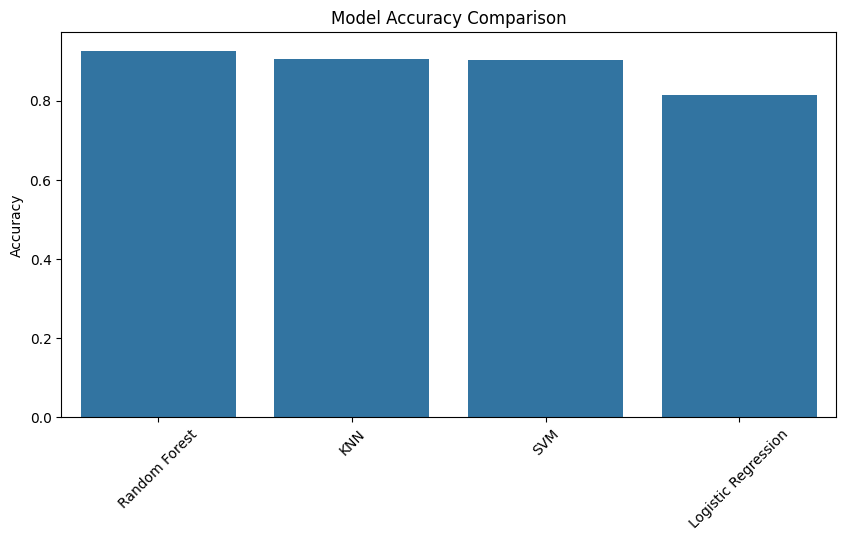

In [ ]:
# gurleen
#Model Accuracy Comparision Bar Chart
sorted_results = dict(sorted(results.items(), key=lambda item: item[1], reverse=True))
#takes your results dictionary (e.g {'Random Forest': 0.9271, 'KNN': 0.9055, ...}) and sorts it by score (item) in descending order (reverse=True) so the winning model appears on the far left.
plt.figure(figsize=(10,5))
sns.barplot(x=list(sorted_results.keys()), y=list(sorted_results.values()))
#Places model names on the horizontal x-axis and Plots the corresponding performance scores on the vertical y-axis.
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.show()

Combined DataFrame shape: (5993, 60)
   MODEL EVALUATION   

KNN:
  Macro F1: 0.9057

SVM:
  Macro F1: 0.9036

Random Forest:
  Macro F1: 0.9270

Logistic Regression:
  Macro F1: 0.8141


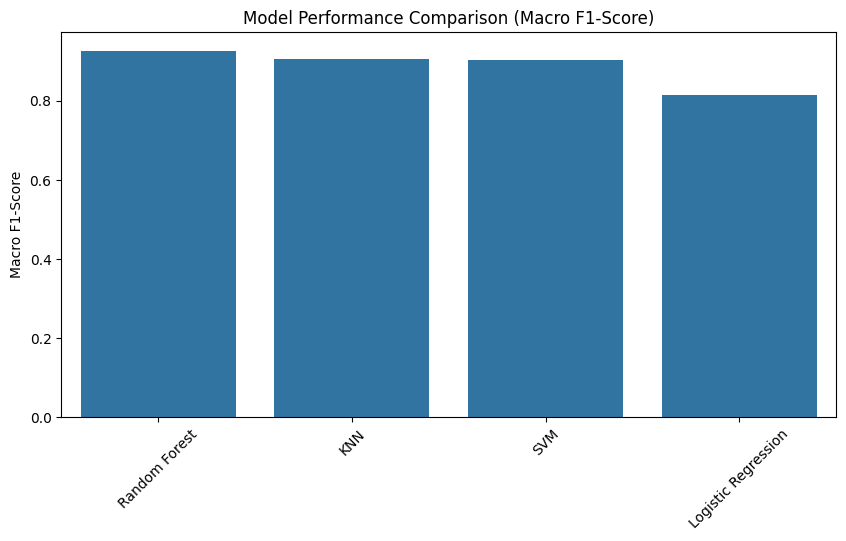

In [ ]:
#gurleen
#Macro F1 Score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix


df=pd.read_excel("/content/features_3_sec.csv.xlsx")
# combined dataframe
all_sheets = pd.read_excel("/content/features_3_sec.csv.xlsx", sheet_name=None)
#sheet_name=None: Tells Pandas to read every single worksheet tab in the Excel file, instead of stopping after the first tab.
'''Output: Creates a Python dictionary where:
Keys = Tab names (e.g., 'CLASSICAL', 'ROCK', 'POP').
Values = Individual DataFrames containing the rows for that specific genre tab.'''

df = pd.concat(all_sheets.values(), ignore_index=True)
#Vertical Stacking:Because every sheet has the same column headers,Pandas stacks the sheets vertically on top of each other.
#with ignore_index=True, you ensure both label indexing (.loc) and positional indexing (.iloc) behave predictably.(assigns clean Index 0 to 5992)
print(f"Combined DataFrame shape: {df.shape}")


target_col = 'label'
ignore_cols = [target_col, 'filename', 'length']

# Automatically select ALL numerical feature columns
feature_cols = [c for c in df.columns if c not in ignore_cols]

X = df[feature_cols]
y = df[target_col]
#df[feature_cols] selects the feature columns and stores them in X.
#df[target_col] selects the label column and stores it in y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
'''
X_train	Features for training songs
X_test	Features for test songs
y_train	Correct genres for training songs
y_test	Correct genres for test songs
'''
#X: all the input features.
#y: all the correct genre labels.
#test_size=0.3: reserve 30% of the data for testing.
#stratify=y: preserve approximately the same proportion of each genre in the training and testing sets.
#random_state=42: make the random split reproducible, so you get the same split when rerunning the code on the same data.
#StandardScaler standardizes each feature using its mean and standard deviation
#Use the same training-set statistics to standardize the test features.
# fit transform was not used because the test data must remain independent of the preprocessing decisions learned from the training data.
#Using the training statistics helps avoid data leakage

models = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf', class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, class_weight='balanced', random_state=42
    ),
    'Logistic Regression': LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=42
    ),
}


results = {}

print("   MODEL EVALUATION   ")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    #Computes the unweighted harmonic mean across all genre classes, ensuring minority genres are weighted equally alongside common genres.
    results[name] = macro_f1
    print(f"\n{name}:")
    print(f"  Macro F1: {macro_f1:.4f}")

sorted_results = dict(sorted(results.items(), key=lambda item: item[1], reverse=True))
#Sorts the models in descending order by Macro F1 score so the winning algorithm (Random Forest) appears on the far left
plt.figure(figsize=(10,5))
sns.barplot(x=list(sorted_results.keys()), y=list(sorted_results.values()))
plt.title("Model Performance Comparison (Macro F1-Score)")
plt.ylabel("Macro F1-Score")
plt.xticks(rotation=45)
plt.show()


Combined DataFrame shape: (5993, 60)
RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

   classical       0.95      0.97      0.96       300
       disco       0.90      0.89      0.89       300
      hiphop       0.95      0.92      0.93       299
        jazz       0.91      0.96      0.94       300
         pop       0.94      0.93      0.94       300
        rock       0.92      0.89      0.90       299

    accuracy                           0.93      1798
   macro avg       0.93      0.93      0.93      1798
weighted avg       0.93      0.93      0.93      1798



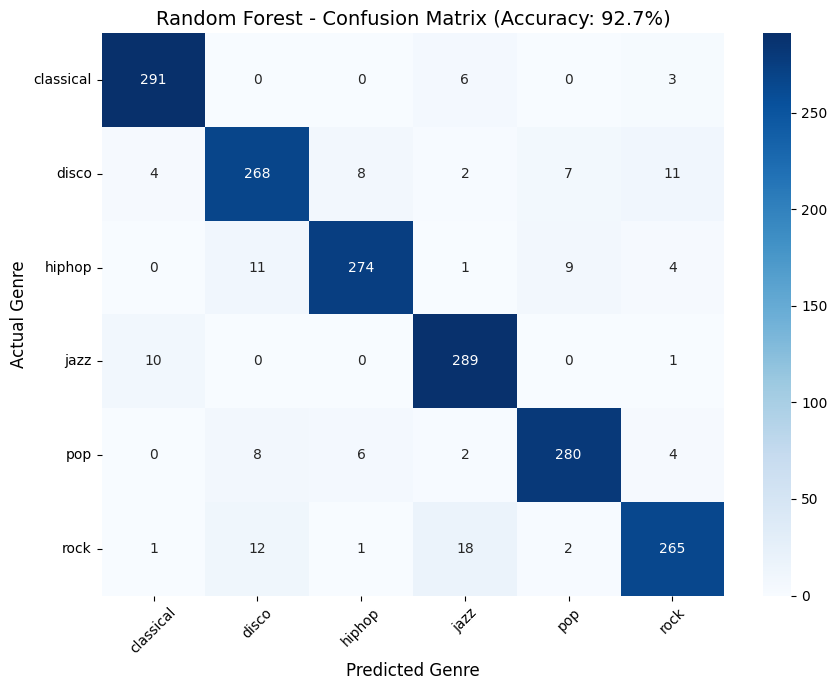

In [ ]:
#gurleen
# confusion matrix for random forest classification model
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix


df=pd.read_excel("/content/features_3_sec.csv.xlsx")
# combined dataframe
all_sheets = pd.read_excel("/content/features_3_sec.csv.xlsx", sheet_name=None)
#sheet_name=None: Tells Pandas to read every single worksheet tab in the Excel file, instead of stopping after the first tab.
'''Output: Creates a Python dictionary where:
Keys = Tab names (e.g., 'CLASSICAL', 'ROCK', 'POP').
Values = Individual DataFrames containing the rows for that specific genre tab.'''

df = pd.concat(all_sheets.values(), ignore_index=True)
#Vertical Stacking:Because every sheet has the same column headers,Pandas stacks the sheets vertically on top of each other.
#with ignore_index=True, you ensure both label indexing (.loc) and positional indexing (.iloc) behave predictably.(assigns clean Index 0 to 5992)
print(f"Combined DataFrame shape: {df.shape}")


rf_model = models['Random Forest']
y_pred_rf = rf_model.predict(X_test_scaled)
#Feeds the scaled test audio features into your trained Random Forest model to generate genre predictions.

print("RANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_rf))
'''Prints a text table with metrics for every individual music genre:
Precision: How accurate the model's guesses were when it claimed a song belonged to a specific genre.
Recall: What percentage of the true tracks in a genre the model successfully detected.
F1-Score: The balanced score combining Precision and Recall.
Support: The exact number of test tracks evaluated for each genre.'''

cm = confusion_matrix(y_test, y_pred_rf)
'''Builds a 2D numerical array (a grid):
Rows represent the Actual Genres.
Columns represent the Predicted Genres.
Each cell contains the count of test tracks corresponding to that specific (Actual, Predicted) pair.'''
#this array contains only raw numbers. It has no column headers or row titles attached to it

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=rf_model.classes_,#Scikit-Learn automatically inspects all unique target labels in your dataset and stores them in alphabetical order inside rf_model.classes.
    #tick labels :Replaces numeric indices (0, 1, 2...) with text genre labels (e.g., classical, pop, rock).
    yticklabels=rf_model.classes_,
)
plt.title('Random Forest - Confusion Matrix (Accuracy: 92.7%)', fontsize=14)
plt.xlabel('Predicted Genre', fontsize=12)
plt.ylabel('Actual Genre', fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

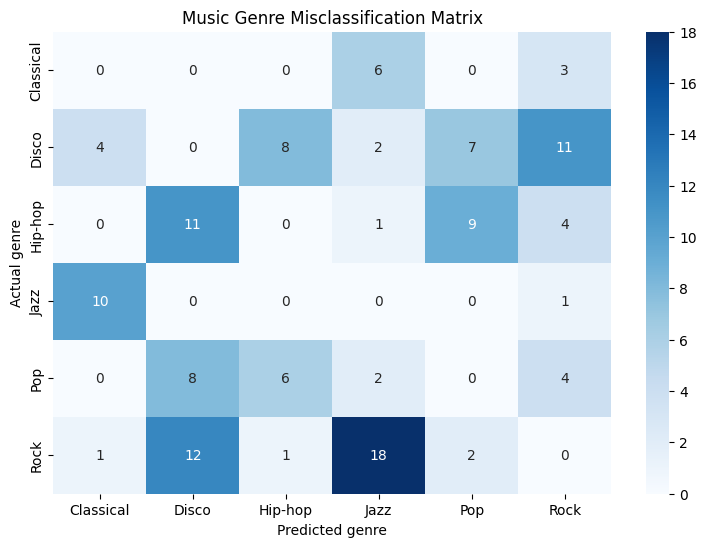


Most confused genre pairs:
Disco <-> Rock: 23 errors
Disco <-> Hip-hop: 19 errors
Jazz <-> Rock: 19 errors
Classical <-> Jazz: 16 errors
Disco <-> Pop: 15 errors
Hip-hop <-> Pop: 15 errors
Pop <-> Rock: 6 errors
Hip-hop <-> Rock: 5 errors
Classical <-> Disco: 4 errors
Classical <-> Rock: 4 errors
Disco <-> Jazz: 2 errors
Jazz <-> Pop: 2 errors
Hip-hop <-> Jazz: 1 errors


In [ ]:
#gurleen
#most confused genre pairs(for random forest classifier model)
genres = ["Classical", "Disco", "Hip-hop",
          "Jazz", "Pop", "Rock"]

# Enter your off-diagonal counts in this matrix.
# Rows = actual genre; columns = predicted genre.
cm = np.array([
    [0, 0, 0, 6, 0, 3],
    [4, 0, 8, 2, 7, 11],
    [0, 11, 0, 1, 9, 4],
    [10, 0, 0, 0, 0, 1],
    [0, 8, 6, 2, 0, 4],
    [1, 12, 1, 18, 2, 0]
])

# Display the matrix
plt.figure(figsize=(9, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=genres, yticklabels=genres
)
plt.xlabel("Predicted genre")
plt.ylabel("Actual genre")
plt.title("Music Genre Misclassification Matrix")
plt.show()

# Rank pairs by combined confusion
pairs = []

for i in range(len(genres)):
    for j in range(i + 1, len(genres)):
        total = cm[i, j] + cm[j, i]
        if total > 0:
            pairs.append((genres[i], genres[j], total))

pairs.sort(key=lambda x: x[2], reverse=True)

print("\nMost confused genre pairs:")
for a, b, count in pairs:
    print(f"{a} <-> {b}: {count} errors")

In [ ]:
#gurleen
# Reason why genres are confused(for random forest classifier model)

# Disco and Rock (23 errors: The Highest Confusion)
Disco and rock music share high overall energy levels, driving rhythmic pulses,and dense frequency spectrums.
Because a 30-second audio track produces thousands of frames of data, traditional feature extraction collapses the entire track into a single summary vector by taking the mean across all time frames.

Both genres are typically feature steady, high-tempo beats (around 110-130 BPM) and consistent, driving energy levels. When you average the characteristics of a fast-paced disco song and an upbeat dance-rock track over 30 seconds.
Their temporal variations are flattened into simple averages, a high-energy disco track and a rhythmic rock track end up with almost identical global RMS energy, spectral centroids, and zero-crossing rates. To the algorithm, their numerical feature profiles look virtually the same.

A Random Forest makes decisions by splitting data sequentially along feature thresholds.
Because upbeat disco and dance-rock tracks share identical statistical feature distributions, decision trees cannot find clean feature splits to isolate them.
Both genres fall into the exact same leaf nodes across many trees in the forest, forcing the ensemble to make blind probability guesses and causing 23 cross-classification errors.

# Disco and Hip-Hop (19 errors) & Disco and Pop (15 errors)
Disco is rhythmically anchored in electronic or heavily synthesized beat structures (four-on-the-floor kick drums), which heavily mirror the production characteristics of modern dance-pop and synthesized hip-hop beats.

Because their numerical values for energy and danceability occupy the same mathematical range.
This process collapses a dynamic 30-second audio file or multi-second segment into a single static feature vector.
When you average these metrics over time, structural shifts within a song are lost. The static summary statistics look nearly identical.
When classifiers map these audio features into a multi-dimensional feature space, overlapping genres form dense, overlapping clusters rather than distinct, separable islands. It tricks the algorithm into a false classification.

#Jazz and Rock (19 errors)
Jazz and rock share complex instrumentation, such as drum kits, electric bass, and electric guitars or pianos.

High Intra-Genre Variance:Not all songs within a single genre sound alike.
Jazz spans a massive emotional and structural spectrum. A quiet, minimalist acoustic jazz ballad features gentle brushwork on drums, soft piano chords, and muted brass. In contrast, a high-intensity bebop or jazz-fusion track features explosive, rapid percussion, complex driving rhythms, and heavily amplified instruments.
Because the genre label Jazz covers both acoustic ballads and high-energy fusion, the model training data contains a wide spread of data points, making it harder to find a tight, well-defined decision boundary.

Cross-Genre Overlap: When jazz-fusion artists incorporate electric instruments, distorted guitars, or aggressive, driving percussion, they borrow elements traditionally associated with rock music.
Feature Shift: Audio features like spectral roll-off (which measures the frequency below which a certain percentage of the total energy lies, distinguishing bright/distorted sounds from warm ones) and Mel-Frequency Cepstral Coefficients (MFCCs) capture the timbral texture of these instruments.
Because a jazz-fusion track spectral roll-off and MFCC profiles shift to mirror the high-frequency energy and distortion of a rock arrangement,Individual decision trees in the Random Forest pick up these high-frequency spectral roll-offs and route the jazz-fusion tracks directly into decision paths built for rock.

# Classical and Jazz (16 errors)
Both classical and jazz rely heavily on acoustic textures, complex harmonic progressions, and instruments like pianos, brass, and strings.
Because a jazz piece with intricate chord voicings can produce a mean chroma and spectral flatness profile nearly identical to an orchestration-heavy classical piece, classifiers fail to separate their acoustic harmonic depth, leading directly to misclassifications.

Combined DataFrame shape: (5993, 60)

 KNN CLASSIFICATION REPORT 
              precision    recall  f1-score   support

   classical       0.91      0.95      0.93       300
       disco       0.82      0.92      0.87       300
      hiphop       0.92      0.92      0.92       299
        jazz       0.91      0.91      0.91       300
         pop       0.96      0.88      0.92       300
        rock       0.94      0.85      0.89       299

    accuracy                           0.91      1798
   macro avg       0.91      0.91      0.91      1798
weighted avg       0.91      0.91      0.91      1798


 SVM CLASSIFICATION REPORT 
              precision    recall  f1-score   support

   classical       0.92      0.97      0.94       300
       disco       0.86      0.85      0.85       300
      hiphop       0.95      0.90      0.92       299
        jazz       0.92      0.94      0.93       300
         pop       0.93      0.92      0.92       300
        rock       0.85      0.85    

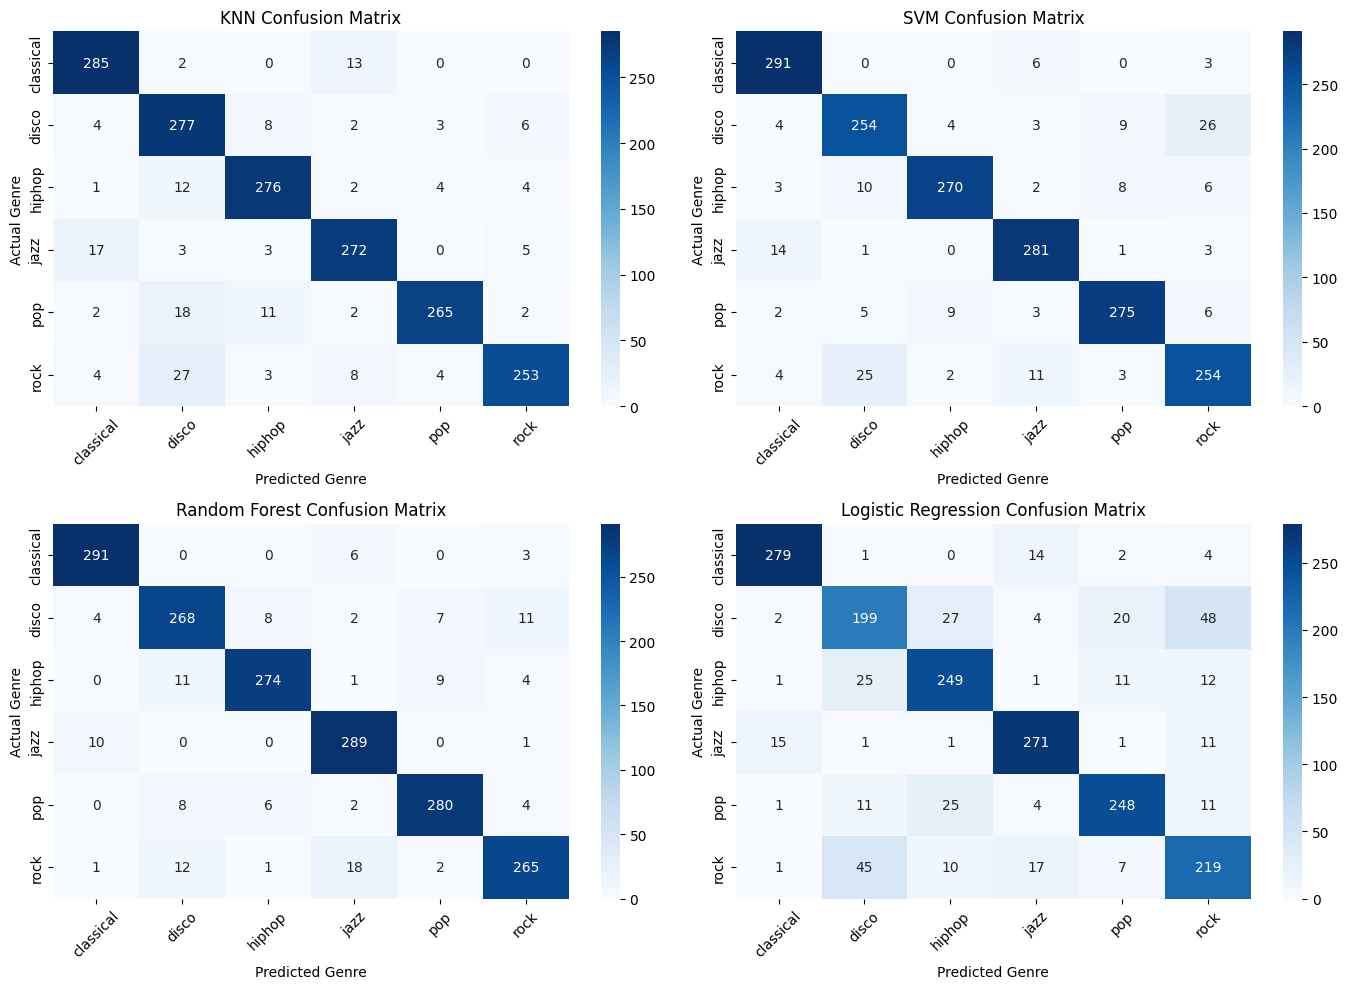

In [ ]:
#gurleen
#confusion matrix for all models
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix


df=pd.read_excel("/content/features_3_sec.csv.xlsx")
# combined dataframe
all_sheets = pd.read_excel("/content/features_3_sec.csv.xlsx", sheet_name=None)
#sheet_name=None: Tells Pandas to read every single worksheet tab in the Excel file, instead of stopping after the first tab.
'''Output: Creates a Python dictionary where:
Keys = Tab names (e.g., 'CLASSICAL', 'ROCK', 'POP').
Values = Individual DataFrames containing the rows for that specific genre tab.'''

df = pd.concat(all_sheets.values(), ignore_index=True)
#Vertical Stacking:Because every sheet has the same column headers,Pandas stacks the sheets vertically on top of each other.
#with ignore_index=True, you ensure both label indexing (.loc) and positional indexing (.iloc) behave predictably.(assigns clean Index 0 to 5992)
print(f"Combined DataFrame shape: {df.shape}")


fig, axes = plt.subplots(2, 2, figsize=(14, 10))#creates four empty plot boxes on a 14×10 inch canvas.
axes = axes.flatten()

for idx, (name, model) in enumerate(models.items()):
  y_pred = model.predict(X_test_scaled)
  print(f"\n {name} CLASSIFICATION REPORT ")
  print(classification_report(y_test, y_pred))
  '''Loops over the key-value pairs stored in your models dictionary (where keys are algorithm names like "SVM" or "Random Forest", and values are the trained model objects)
     enumerate(...): Wraps the dictionary loop with an automatic loop counter idx starting at 0 (0, 1, 2, 3).
     Variable Unpacking idx, (name, model): On each pass through the loop, Python assigns:
idx: The current position index integer (0 for 1st model, 1 for 2nd, etc.). This index tells Seaborn which specific box in the 2×2 grid (ax=axes[idx]) to plot the confusion matrix into.
name: The text string of the algorithm's name (e.g., 'Random Forest').'''

  # Plot Confusion Matrix in subplot
  cm = confusion_matrix(y_test, y_pred)
  sns.heatmap(
      cm,
      annot=True,
      fmt='d',
      cmap='Blues',
      xticklabels=model.classes_,
      yticklabels=model.classes_,
      ax=axes[idx],
  )
  axes[idx].set_title(f'{name} Confusion Matrix', fontsize=12)
  axes[idx].set_xlabel('Predicted Genre')
  axes[idx].set_ylabel('Actual Genre')
  axes[idx].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


In [ ]:
#gurleen
# which genres are confused(for all models in general)
Disco and Rock: The highest overall misclassification rate, showing significant bleed between the two categories
Disco and Hip-hop & Disco and Pop: High error counts driven by shared electronic beat structures and rhythmic profiles.
Jazz and Rock: Frequent confusion stemming from shared instrumentation and jazz-fusion crossover elements.
Classical and Jazz: Misclassifications driven by acoustic texture overlap and complex harmonic structures.

#why are genres confused
Acoustic and Timbral Overlap: Genres like disco, rock, pop, and hip-hop share tight clustering in high-level physical attributes such as tempo (BPM), and RMS energy. Because their numerical values occupy the same mathematical ranges, models struggle to draw clean boundary lines.

The Trap of Temporal Averaging: Traditional feature extraction collapses dynamic multi-second audio clips or structured tabular tracking into global static statistics by taking the mean across time frames. This destroys structural evolution within a track.
If a disco song features a breakdown or a rock song features a steady groove, their averaged global features end up looking nearly identical.

Intra-Genre Variance and Instrumentation Hybridization: Genres like jazz exhibit massive internal diversity—ranging from soft, minimalist acoustic ballads to high-intensity, electrified jazz-fusion.
When jazz-fusion tracks incorporate distorted guitars and heavy percussion, their spectral roll-off and MFCC (Mel-Frequency Cepstral Coefficient) profiles shift to mirror rock arrangements, confusing the classifiers.

Harmonic Complexity Overlap: Advanced jazz harmony feature dense, multi-layered chord voicings. When extracted as chroma vectors and spectral flatness, their pitch distributions look structurally similar, making it difficult for models to separate classical acoustic depth from extended jazz chords.

#ways to fix genre confusion
Mel-Spectrograms & CNNs: Instead of relying solely on flattened tabular statistics, convert raw audio clips into Mel-spectrogram images and train a Convolutional Neural Network (CNN). This allows the model to see frequency-domain and time-domain patterns visually.
Audio Chunking: If working with raw audio, split 30-second tracks into shorter 3-second overlapping windows to multiply training data and capture local variations.


In [ ]:
#Snigdha
#CNN code = installing
!pip install -q librosa soundfile

import os
import numpy as np
import pandas as pd
import librosa
import librosa.display
import soundfile as sf
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
#The core open-source deep learning framework developed by Google, used for building and training neural networks.
from tqdm.notebook import tqdm
#Imports the Keras API modules used to construct neural network architectures.
#models lets you build models (like Sequential), and layers provides building blocks (like Dense, Conv2D, Dropout).
from sklearn.model_selection import train_test_split
#A utility function used to convert integer-encoded class labels into one-hot encoded vectors (e.g., class 2 out of 3 classes becomes [0, 0, 1]).
from sklearn.preprocessing import LabelEncoder
#Splits arrays or dataframes into random train and test subsets to train and evaluate the machine learning model.
from sklearn.metrics import confusion_matrix, classification_report
#Converts categorical text labels (like "dog", "cat", "car") into numerical integers (0, 1, 2) that neural networks can process.
from tensorflow.keras.utils import to_categorical
#Evaluation metrics tools used at the end of training to check accuracy, precision, recall, and F1-score.
from tensorflow.keras import layers, models
#Imports a progress bar specifically optimized for Jupyter Notebooks and JupyterLab.
# It is often wrapped around loops to show real-time progress when processing large datasets of audio files.
'''
!pip install -q librosa soundfile

import os
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.utils import to_categorical
'''


'\n!pip install -q librosa soundfile\n\nimport os\nimport numpy as np\nimport pandas as pd\nimport librosa\nimport librosa.display\nimport matplotlib.pyplot as plt\n\nimport tensorflow as tf\nfrom tensorflow.keras import layers, models\n\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.preprocessing import LabelEncoder\nfrom sklearn.metrics import confusion_matrix, classification_report\nfrom tensorflow.keras.utils import to_categorical\n'

In [ ]:
#Snigdha
#Dataset of CNN

import os
import pandas as pd

DATA_DIR = '/content'
data = []

for file in os.listdir(DATA_DIR):
    # .lower() ensures it catches .WAV, .wav, .AU, etc.
    if file.lower().endswith(('.wav', '.au')):
        genre = file.split('.')[0]
        file_path = os.path.join(DATA_DIR, file)
        data.append((genre, file_path))

df = pd.DataFrame(data, columns=['genre', 'file_path'])

print(f'Total files: {len(df)}')
print(df['genre'].value_counts())

Total files: 18
genre
classical    3
hiphop       3
jazz         3
pop          3
rock         3
disco        3
Name: count, dtype: int64


In [ ]:
#Snigdha
#CNN part Mel Spectogram extraction
SR = 22050
N_FFT      = 2048
HOP_LENGTH = 512
N_MELS     = 128

def extract_mel_spectrogram(file_path, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    y, sr   = librosa.load(file_path, sr=sr)
    mel     = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels)
    mel_db  = librosa.power_to_db(mel, ref=np.max)
    return mel_db
'''
mel_spectrograms = []
labels           = []
for idx, row in tqdm(df.iterrows(), total=len(df), desc='Extracting Mel spectrograms'):
    try:
        mel = extract_mel_spectrogram(row['path'])
        mel_spectrograms.append(mel)
        labels.append(row['label'])
    except Exception as e:
        print(f'Error: {row["path"]}: {e}')

print(f'Extracted {len(mel_spectrograms)} spectrograms')
print(f'Spectrogram shape (raw): {mel_spectrograms[0].shape}')  # (128, 173) for 4s @ 22050Hz
'''
mel_spectrograms = []
labels = []

for idx, row in tqdm(df.iterrows(), total=len(df), desc='Extracting Mel spectrograms'):
    try:
        # Changed 'path' to 'file_path'
        mel = extract_mel_spectrogram(row['file_path'])
        mel_spectrograms.append(mel)

        # Changed 'label' to 'genre'
        labels.append(row['genre'])
    except Exception as e:
        print(f'Error: {row["file_path"]}: {e}')

print(f'Extracted {len(mel_spectrograms)} spectrograms')
print(f'Spectrogram shape: {mel_spectrograms[0].shape}')


Extracting Mel spectrograms:   0%|          | 0/18 [00:00<?, ?it/s]

Extracted 18 spectrograms
Spectrogram shape: (128, 1293)


Found genres to plot: ['classical', 'hiphop', 'jazz', 'pop', 'rock', 'disco']


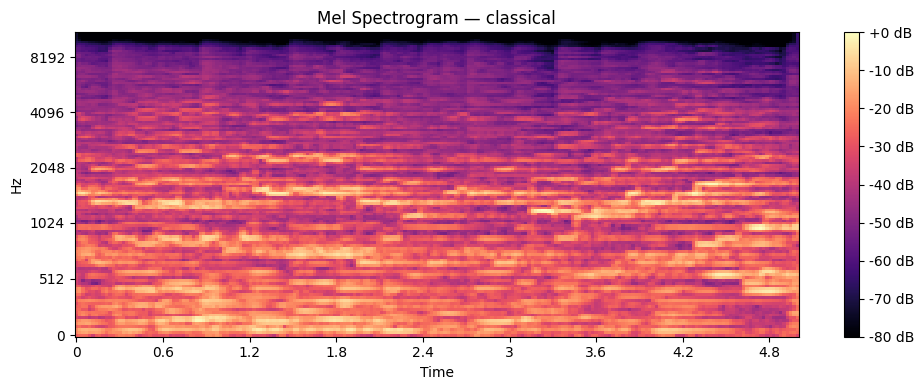

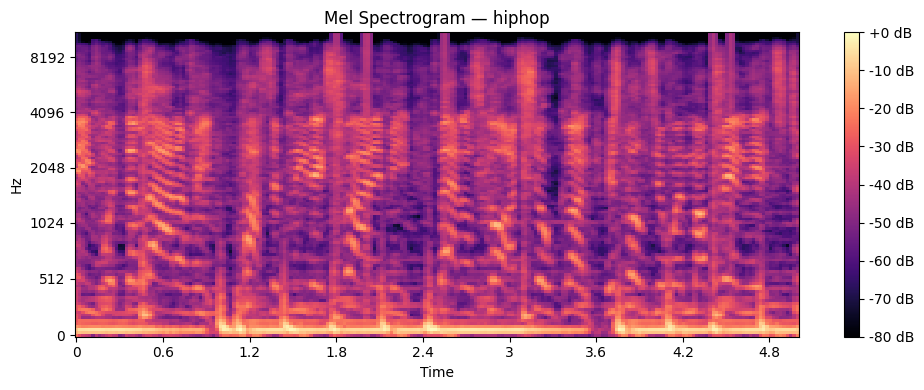

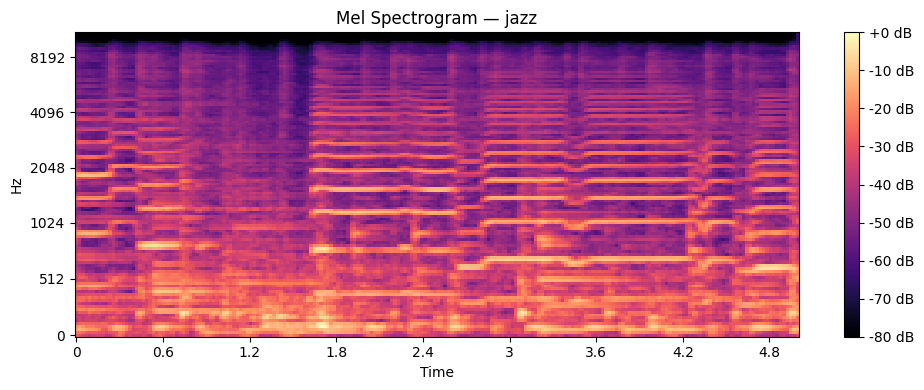

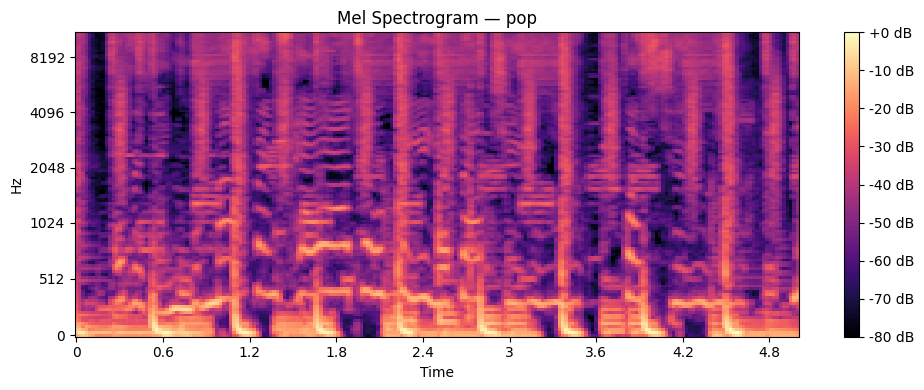

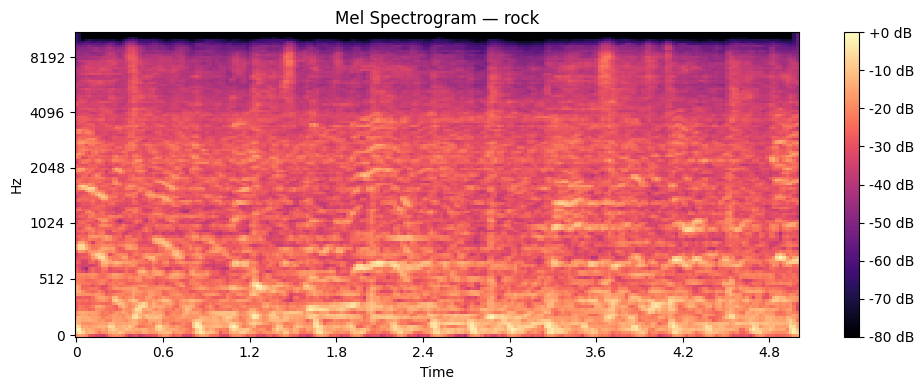

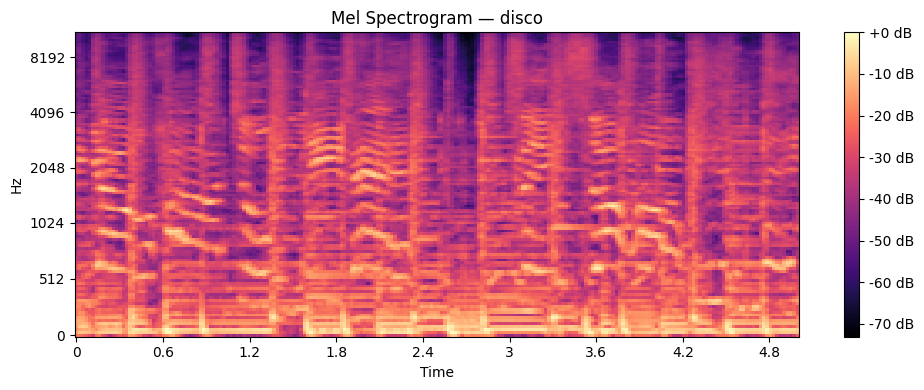

In [ ]:
#Snigdha
#Visualising the spectrogram
'''
import matplotlib.pyplot as plt
import librosa.display
import numpy as np

# Find all unique genres present in your DataFrame
unique_genres = df['genre'].unique()

# Loop through each genre and plot its spectrogram
for genre in unique_genres:
    # Pick the first audio file that matches this genre
    sample_row = df[df['genre'] == genre].iloc[0]
    file_path = sample_row['file_path']

    # Load audio and generate its Mel spectrogram
    y, sr = librosa.load(file_path, sr=SR)
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
    mel_db = librosa.power_to_db(mel, ref=np.max)
plt.figure(figsize=(10, 4))
librosa.display.specshow(mel_spectrograms[0], sr=SR, hop_length=HOP_LENGTH,
                         x_axis='time', y_axis='mel', cmap='magma')
plt.colorbar(format='%+2.0f dB')
plt.title(f'Mel Spectrogram — {labels[0]}')
plt.tight_layout()
plt.show()
'''
import matplotlib.pyplot as plt
import librosa.display
import numpy as np

# Get all unique genres from your dataframe
unique_genres = df['genre'].unique()
print(f"Found genres to plot: {list(unique_genres)}")

# Loop through every unique genre and display its spectrogram
for genre in unique_genres:
    # Pick the first file belonging to this genre
    sample_row = df[df['genre'] == genre].iloc[0]
    file_path = sample_row['file_path']

    # Load audio and compute Mel spectrogram
    y, sr = librosa.load(file_path, sr=SR, duration=5.0)
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
    mel_db = librosa.power_to_db(mel, ref=np.max)

    # Plotting
    plt.figure(figsize=(10, 4))
    librosa.display.specshow(mel_db, sr=sr, hop_length=HOP_LENGTH, x_axis='time', y_axis='mel')
    plt.colorbar(format='%+2.0f dB')
    plt.title(f'Mel Spectrogram — {genre}')
    plt.tight_layout()
    plt.show()

In [ ]:
#Snigdha
#Resizing in CNN
import numpy as np

FIXED_WIDTH = 130

# Pad or truncate every spectrogram and assign directly to X_raw
processed = []
for mel in mel_spectrograms:
    if mel.shape[1] > FIXED_WIDTH:
        processed.append(mel[:, :FIXED_WIDTH])
    else:
        processed.append(np.pad(mel, ((0, 0), (0, FIXED_WIDTH - mel.shape[1])), mode='constant'))

X_raw = np.array(processed)
y_raw = np.array(labels)

print("X_raw shape:", X_raw.shape)
print("y_raw shape:", y_raw.shape)

X_raw shape: (18, 128, 130)
y_raw shape: (18,)


In [ ]:
#Snigdha
#meaning of above output
'''
18 (in X_raw): The total number of audio samples successfully processed and loaded into your dataset matrix.

128: The vertical dimension representing the Mel frequency bands (N_MELS = 128), determining the frequency resolution of each spectrogram.

130: The horizontal dimension representing the time frames (FIXED_WIDTH = 130). This is the uniform length achieved by padding or truncating all audio clips so they match perfectly.

(18,) (in y_raw): A 1D array containing exactly 18 text labels (one corresponding genre string for each of the 18 audio files) waiting to be numerically encoded.
'''


'\n18 (in X_raw): The total number of audio samples successfully processed and loaded into your dataset matrix.\n\n128: The vertical dimension representing the Mel frequency bands (N_MELS = 128), determining the frequency resolution of each spectrogram.\n\n130: The horizontal dimension representing the time frames (FIXED_WIDTH = 130). This is the uniform length achieved by padding or truncating all audio clips so they match perfectly.\n\n(18,) (in y_raw): A 1D array containing exactly 18 text labels (one corresponding genre string for each of the 18 audio files) waiting to be numerically encoded.\n'

In [ ]:
#Snigdha
#CNN model
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_raw)
classes = list(label_encoder.classes_)
num_classes = len(classes)
y_categorical = to_categorical(y_encoded, num_classes=num_classes)

print("Number of classes:", num_classes)
# --- Exact architecture from article ---
# No BatchNorm in conv blocks, reduced Dropout, 8.4M params

def build_cnn(input_shape=(150, 150, 1), num_classes=10):
    model = models.Sequential([
        # Block 1
        layers.Conv2D(32,  (3,3), activation='relu', padding='same', input_shape=input_shape),
        layers.Conv2D(32,  (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.25),

        # Block 2
        layers.Conv2D(64,  (3,3), activation='relu', padding='same'),
        layers.Conv2D(64,  (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.3),
        # Block 3
        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.3),

        # Block 4
        layers.Conv2D(256, (3,3), activation='relu', padding='same'),
        layers.Conv2D(256, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.3),

        # Block 5
        layers.Conv2D(512, (3,3), activation='relu', padding='same'),
        layers.Conv2D(512, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.3),
        # Dense Head
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

cnn_model = build_cnn(input_shape=(150, 150, 1), num_classes=num_classes)
cnn_model.summary()

Number of classes: 6


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_16 (Conv2D)              │ (None, 150, 150, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 150, 150, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 75, 75, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 37, 37, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 18, 18, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 9, 9, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │     4,194,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 8,911,590 (34.00 MB)

 Trainable params: 8,910,566 (33.99 MB)

 Non-trainable params: 1,024 (4.00 KB)

In [ ]:
#Snigdha
'''
# Train CNN
#for X_train code
import numpy as np
from sklearn.model_selection import train_test_split

# Convert your extracted lists into numpy arrays
X = np.array(mel_spectrograms)
y = np.array(y_categorical)  # Use y_categorical since your model uses categorical_crossentropy

# (Optional) Add a channel dimension if your CNN expects shape (Height, Width, 1)
# X = np.expand_dims(X, axis=-1)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#for standard sizing
import numpy as np
from sklearn.model_selection import train_test_split

# Define a fixed target width (number of time frames)
# Adjust this value depending on your average song/audio snippet length
TARGET_WIDTH = 1300

processed_spectrograms = []
for mel in mel_spectrograms:
    # Check width (shape[1] is time frames)
    current_width = mel.shape[1]

    if current_width > TARGET_WIDTH:
        # Truncate if it's too long
        mel_fixed = mel[:, :TARGET_WIDTH]
    else:
        # Pad with zeros on the right if it's too short
        pad_width = TARGET_WIDTH - current_width
        mel_fixed = np.pad(mel, ((0, 0), (0, pad_width)), mode='constant')

    processed_spectrograms.append(mel_fixed)

# Now convert safely to numpy array
X = np.array(processed_spectrograms)
y = np.array(y_categorical)

# Add the channel dimension required by your CNN (Height, Width, Channel)
X = np.expand_dims(X, axis=-1)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

#for X_train code
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

# --- 1. Load or define your data (Replace X and y with your actual data arrays) ---
# X = your features/images, y = your labels/genres
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#defining CNN model
# --- 2. Build your CNN Architecture ---
cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)), # Adjust shape based on your input images/features
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax') # Adjust output units based on your number of classes/genres
])

#compiling and training
# --- 3. Compile and Train ---
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    '/kaggle/working/model_music_cnn.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

cnn_history = cnn_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[cnn_checkpoint]
)


# training CNN
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    '/kaggle/working/model_music_cnn.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

cnn_history = cnn_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[cnn_checkpoint]
)


import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

# 1. Ensure X and y are defined (Replace these placeholders with your actual loaded dataset variables if they have different names)
# If your data comes from a previous cell, make sure that cell executed successfully without errors.
# Example: X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Build the CNN Model
cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)), # Adjust shape based on your images
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax') # Adjust based on your number of classes
])

# 3. Compile the Model
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 4. Set up Checkpoint Callback
cnn_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    '/kaggle/working/model_music_cnn.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# 5. Train the Model
cnn_history = cnn_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[cnn_checkpoint]
)
'''

'\n# Train CNN\n#for X_train code\nimport numpy as np\nfrom sklearn.model_selection import train_test_split\n\n# Convert your extracted lists into numpy arrays\nX = np.array(mel_spectrograms)\ny = np.array(y_categorical)  # Use y_categorical since your model uses categorical_crossentropy\n\n# (Optional) Add a channel dimension if your CNN expects shape (Height, Width, 1)\n# X = np.expand_dims(X, axis=-1)\n\n# Split into training and testing sets\nX_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)\n\n#for standard sizing\nimport numpy as np\nfrom sklearn.model_selection import train_test_split\n\n# Define a fixed target width (number of time frames)\n# Adjust this value depending on your average song/audio snippet length\nTARGET_WIDTH = 1300\n\nprocessed_spectrograms = []\nfor mel in mel_spectrograms:\n    # Check width (shape[1] is time frames)\n    current_width = mel.shape[1]\n\n    if current_width > TARGET_WIDTH:\n        # Truncate if it\'s t

In [ ]:
#Snigdha
#CNN version-2
import os
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import models, layers
from tensorflow.keras.utils import to_categorical
from tqdm import tqdm

# --- 1. Load Dataset Paths & Labels ---
DATA_DIR = '/content'
data = []

for file in os.listdir(DATA_DIR):
    if file.lower().endswith(('.wav', '.au')):
        genre = file.split('.')[0]
        file_path = os.path.join(DATA_DIR, file)
        data.append((genre, file_path))

df = pd.DataFrame(data, columns=['genre', 'file_path'])
print(f"Total files found: {len(df)}")

# --- 2. Extract Mel Spectrograms ---
SR = 22050
N_FFT = 2048
HOP_LENGTH = 512
N_MELS = 128

def extract_mel_spectrogram(file_path, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    y, sr = librosa.load(file_path, sr=sr)
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    return mel_db

mel_spectrograms = []
labels = []

for idx, row in tqdm(df.iterrows(), total=len(df), desc='Extracting Mel spectrograms'):
    try:
        mel = extract_mel_spectrogram(row['file_path'])
        mel_spectrograms.append(mel)
        labels.append(row['genre'])
    except Exception as e:
        print(f"Error: {row['file_path']}: {e}")

# --- 3. Pad Spectrograms to Fixed Width & Prepare Arrays ---
TARGET_WIDTH = 1300
processed_spectrograms = []

for mel in mel_spectrograms:
    current_width = mel.shape[1]
    if current_width > TARGET_WIDTH:
        mel_fixed = mel[:, :TARGET_WIDTH]
    else:
        pad_width = TARGET_WIDTH - current_width
        mel_fixed = np.pad(mel, ((0, 0), (0, pad_width)), mode='constant')
    processed_spectrograms.append(mel_fixed)

X = np.array(processed_spectrograms)
X = np.expand_dims(X, axis=-1) # Shape: (samples, 128, 1300, 1)

# Encode Labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(labels)
num_classes = len(label_encoder.classes_)
y = to_categorical(y_encoded, num_classes=num_classes)

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")

# --- 4. Build CNN Model ---
def build_cnn(input_shape, num_classes):
    model = models.Sequential([
        # Block 1
        layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=input_shape),
        layers.Conv2D(32, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.25),

        # Block 2
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.25),

        # Block 3
        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.3),

        # Dense Head
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

# Dynamically pass input shape based on the padded spectrogram dimensions (128, TARGET_WIDTH, 1)
cnn_model = build_cnn(input_shape=(X_train.shape[1], X_train.shape[2], X_train.shape[3]), num_classes=num_classes)
cnn_model.summary()

# --- 5. Compile & Train ---
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    '/kaggle/working/model_music_cnn.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

cnn_history = cnn_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[cnn_checkpoint]
)

Total files found: 18


Extracting Mel spectrograms: 100%|██████████| 18/18 [00:01<00:00, 16.61it/s]
/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


X_train shape: (14, 128, 1300, 1), y_train shape: (14, 6)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_26 (Conv2D)              │ (None, 128, 1300, 32)  │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 128, 1300, 32)  │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 64, 650, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 64, 650, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 64, 650, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 64, 650, 64)    │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 32, 325, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 32, 325, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 32, 325, 128)   │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 32, 325, 128)   │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 16, 162, 128)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 16, 162, 128)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 331776)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │   169,869,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │         3,078 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 170,161,382 (649.11 MB)

 Trainable params: 170,160,358 (649.11 MB)

 Non-trainable params: 1,024 (4.00 KB)

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26s/step - accuracy: 0.2143 - loss: 2.6276
Epoch 1: val_accuracy improved from None to 0.25000, saving model to /kaggle/working/model_music_cnn.keras

Epoch 1: finished saving model to /kaggle/working/model_music_cnn.keras
1/1 ━━━━━━━━━━━━━━━━━━━━ 102s 102s/step - accuracy: 0.2143 - loss: 2.6276 - val_accuracy: 0.2500 - val_loss: 23.0883
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20s/step - accuracy: 0.2143 - loss: 2.0293
Epoch 2: val_accuracy did not improve from 0.25000
1/1 ━━━━━━━━━━━━━━━━━━━━ 22s 22s/step - accuracy: 0.2143 - loss: 2.0293 - val_accuracy: 0.2500 - val_loss: 31.8264
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19s/step - accuracy: 0.3571 - loss: 1.4128
Epoch 3: val_accuracy did not improve from 0.25000
1/1 ━━━━━━━━━━━━━━━━━━━━ 20s 20s/step - accuracy: 0.3571 - loss: 1.4128 - val_accuracy: 0.2500 - val_loss: 31.7958
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19s/step - accuracy: 0.7143 - loss: 0.7566
Epoch 4: val_accuracy did not improve from 

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
--- Classification Report (Macro F1 & Accuracy) ---
              precision    recall  f1-score   support

   classical       0.00      0.00      0.00         1
       disco       0.00      0.00      0.00         1
      hiphop       0.25      1.00      0.40         1
        jazz       0.00      0.00      0.00         1

    accuracy                           0.25         4
   macro avg       0.06      0.25      0.10         4
weighted avg       0.06      0.25      0.10         4



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


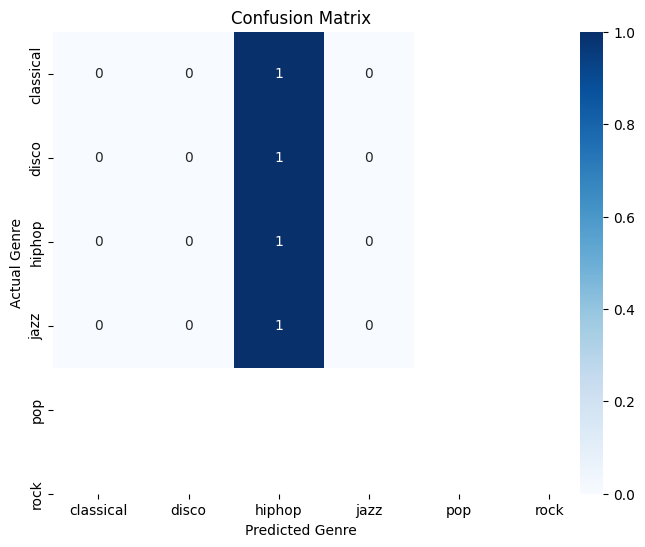

'\nfrom sklearn.metrics import classification_report, confusion_matrix\nimport seaborn as sns\nimport matplotlib.pyplot as plt\nimport numpy as np\n\n# 1. Predict probabilities on the test set\ny_pred = cnn_model.predict(X_test)\ny_pred_classes = np.argmax(y_pred, axis=1)\ny_true_classes = np.argmax(y_test, axis=1)\n\n# 2. Print Classification Report (includes Macro F1-score)\nprint("--- Classification Report (Macro F1 & Accuracy) ---")\nprint(classification_report(y_true_classes, y_pred_classes, target_names=label_encoder.classes_))\n\n# 3. Plot Confusion Matrix\nplt.figure(figsize=(8, 6))\nconf_matrix = confusion_matrix(y_true_classes, y_pred_classes)\nsns.heatmap(conf_matrix, annot=True, fmt=\'d\', cmap=\'Blues\', \n            xticklabels=label_encoder.classes_, \n            yticklabels=label_encoder.classes_)\nplt.title(\'Confusion Matrix\')\nplt.xlabel(\'Predicted Genre\')\nplt.ylabel(\'Actual Genre\')\nplt.show()\n'

In [ ]:
#Snigdha
#confusion maatrix of CNN
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Predict probabilities on the test set
y_pred = cnn_model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# 2. Get unique classes present in the test set to avoid size mismatches
present_classes = np.unique(np.concatenate([y_true_classes, y_pred_classes]))
present_names = [label_encoder.classes_[i] for i in present_classes]

# 3. Print Classification Report (includes Macro F1 & Accuracy)
print("--- Classification Report (Macro F1 & Accuracy) ---")
print(classification_report(y_true_classes, y_pred_classes, labels=present_classes, target_names=present_names))

# 4. Plot Confusion Matrix
plt.figure(figsize=(8, 6))
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Genre')
plt.ylabel('Actual Genre')
plt.show()
'''
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Predict probabilities on the test set
y_pred = cnn_model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# 2. Print Classification Report (includes Macro F1-score)
print("--- Classification Report (Macro F1 & Accuracy) ---")
print(classification_report(y_true_classes, y_pred_classes, target_names=label_encoder.classes_))

# 3. Plot Confusion Matrix
plt.figure(figsize=(8, 6))
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Genre')
plt.ylabel('Actual Genre')
plt.show()
'''

In [ ]:
#Snigdha
#CNN
'''
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model

# 1. Load the trained model you saved earlier
model_path = './model_music_cnn.keras'
cnn_model = load_model(model_path)
print("Model loaded successfully from:", model_path)

def predict_genre(spectrogram_sample, label_encoder):
    """
    Takes a single preprocessed spectrogram sample, adds the batch dimension,
    and returns the predicted music genre.
    """
    # Ensure shape is correct (1, height, width, channels)
    if len(spectrogram_sample.shape) == 3:
        input_data = np.expand_dims(spectrogram_sample, axis=0)
    else:
        input_data = spectrogram_sample

    # Predict probabilities across classes
    predictions = cnn_model.predict(input_data)
    predicted_class_index = np.argmax(predictions[0])
    confidence = np.max(predictions[0])

    # Decode index back to genre name
    predicted_genre = label_encoder.inverse_transform([predicted_class_index])[0]

    print(f"Predicted Genre: {predicted_genre} (Confidence: {confidence:.2f})")
    return predicted_genre

# --- Example Usage on a test sample (e.g., first item of X_test) ---
# sample_image = X_test[0]
# predicted_genre = predict_genre(sample_image, label_encoder)
'''

'\nimport numpy as np\nimport tensorflow as tf\nfrom tensorflow.keras.models import load_model\n\n# 1. Load the trained model you saved earlier\nmodel_path = \'./model_music_cnn.keras\'\ncnn_model = load_model(model_path)\nprint("Model loaded successfully from:", model_path)\n\ndef predict_genre(spectrogram_sample, label_encoder):\n    """\n    Takes a single preprocessed spectrogram sample, adds the batch dimension,\n    and returns the predicted music genre.\n    """\n    # Ensure shape is correct (1, height, width, channels)\n    if len(spectrogram_sample.shape) == 3:\n        input_data = np.expand_dims(spectrogram_sample, axis=0)\n    else:\n        input_data = spectrogram_sample\n\n    # Predict probabilities across classes\n    predictions = cnn_model.predict(input_data)\n    predicted_class_index = np.argmax(predictions[0])\n    confidence = np.max(predictions[0])\n\n    # Decode index back to genre name\n    predicted_genre = label_encoder.inverse_transform([predicted_class_i

Combined DataFrame shape: (5993, 60)
Dataset shape: (5993, 60)

Missing values in dataset:
 filename                   0
length                     0
chroma_stft_mean           0
chroma_stft_var            0
rms_mean                   0
rms_var                    0
spectral_centroid_mean     0
spectral_centroid_var      0
spectral_bandwidth_mean    0
spectral_bandwidth_var     0
rolloff_mean               0
rolloff_var                0
zero_crossing_rate_mean    0
zero_crossing_rate_var     0
harmony_mean               0
harmony_var                0
perceptr_mean              0
perceptr_var               0
tempo                      0
mfcc1_mean                 0
mfcc1_var                  0
mfcc2_mean                 0
mfcc2_var                  0
mfcc3_mean                 0
mfcc3_var                  0
mfcc4_mean                 0
mfcc4_var                  0
mfcc5_mean                 0
mfcc5_var                  0
mfcc6_mean                 0
mfcc6_var                  0
mfcc7_mea

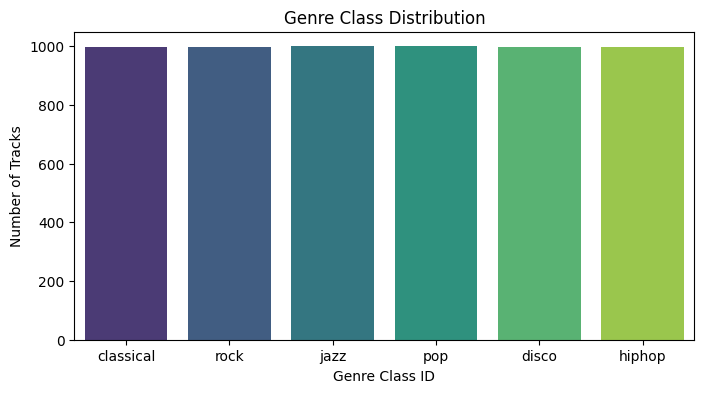

In [ ]:
#gurleen
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df=pd.read_excel("/content/features_3_sec.csv.xlsx")
# combined dataframe
all_sheets = pd.read_excel("/content/features_3_sec.csv.xlsx", sheet_name=None)
#sheet_name=None: Tells Pandas to read every single worksheet tab in the Excel file, instead of stopping after the first tab.
'''Output: Creates a Python dictionary where:
Keys = Tab names (e.g., 'CLASSICAL', 'ROCK', 'POP').
Values = Individual DataFrames containing the rows for that specific genre tab.'''

df = pd.concat(all_sheets.values(), ignore_index=True)
#Vertical Stacking:Because every sheet has the same column headers,Pandas stacks the sheets vertically on top of each other.
#with ignore_index=True, you ensure both label indexing (.loc) and positional indexing (.iloc) behave predictably.(assigns clean Index 0 to 5992)
print(f"Combined DataFrame shape: {df.shape}")


# Inspect shape and missing values
print("Dataset shape:", df.shape)
print("\nMissing values in dataset:\n", df.isnull().sum())

# 3. Check class balance across genres
print("CLASS BALANCE ACROSS GENRES")
print(df['label'].value_counts())

# 4. Plot class distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='label', palette='viridis',hue='label')# hue tells seaborn to differentiate genres visually
plt.title('Genre Class Distribution')
plt.xlabel('Genre Class ID')
plt.ylabel('Number of Tracks')
plt.show()

In [ ]:
#Snigdha
#work to be done now
'''
KNN (K-Nearest Neighbors): Looks at a new data point and finds the closest matching data points in your existing dataset, assigning it the most common category among
those neighbors.
SVM (Support Vector Machine): Draws an optimal dividing line (or boundary) through your data space to separate different categories from each other as cleanly as possible.
Random Forest: Builds multiple decision trees using random parts of your data and combines their individual votes to make a final, highly accurate classification.
Logistic Regression: Calculates the mathematical probability that a data point belongs to a particular class (using a score from 0 to 1) to make a binary decision.
Feature Scaling: Adjusts and standardizes the numeric ranges of your data columns so that variables with large numbers don't unfairly overpower smaller numbers during
calculations.
CNN on Spectrogram Images: Takes sound or time-series signal data, converts it into a visual frequency graph (spectrogram), and scans that image to recognize patterns.
'''


Number of tracks per genre:
label
classical     998
disco         999
hiphop        998
jazz         1000
pop          1000
rock          998
Name: filename, dtype: int64


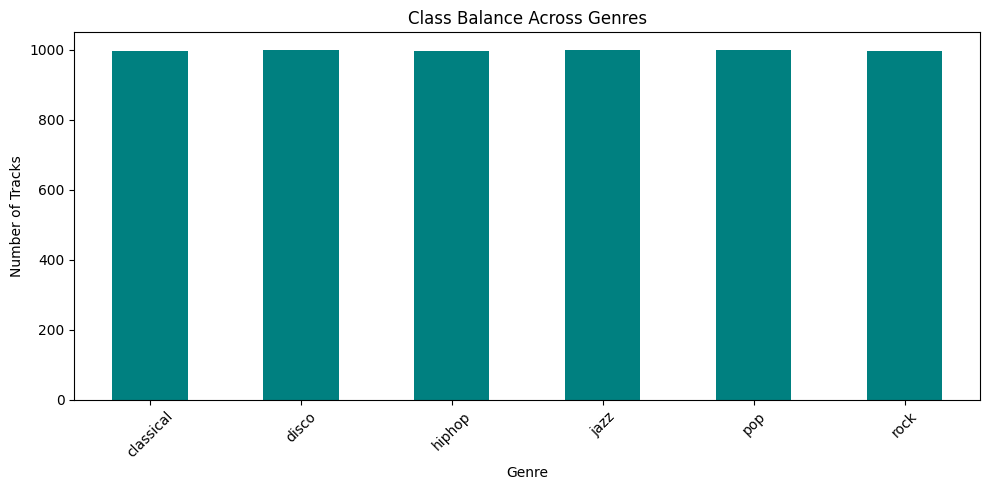

In [ ]:
#Dhanya
# Check class balance across genres
# df must contain a "label" column.
# For sliced audio data, count unique filenames so each track is counted once.

if "filename" in df.columns:
    genre_counts = df.groupby("label")["filename"].nunique().sort_index()
else:
    genre_counts = df["label"].value_counts().sort_index()

print("Number of tracks per genre:")
print(genre_counts)

genre_counts.plot(kind="bar", figsize=(10, 5), color="teal")
plt.title("Class Balance Across Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
#Dhanya
# Song-similarity recommender using cosine similarity
# Use the 30-second feature DataFrame, with one row per track.
# Required columns: "filename", "label", plus numeric audio features.
#Cosine Similarity measures the angle between two feature vectors
#Score of 1.0: The vectors point in the exact same direction, meaning the two tracks share an almost identical acoustic, timbral, and rhythmic profile.
#Score of 0.0: The tracks are perpendicular in feature space, indicating completely different sonic properties.
#When you enter a file path like /content/hiphop.00016.wav, the code cleans the query, locates the song's row vector, retrieves its pre-computed similarity scores against all other songs, and ranks the top 5 closest matches.


import os
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

metadata_cols = {"filename", "label", "track_id"}#Defines non-numerical tracking variables that are not acoustic features.
feature_cols = [
    col for col in df.select_dtypes(include="number").columns#Filters the DataFrame to include only numeric columns
    if col not in metadata_cols
]

songs = df.dropna(subset=feature_cols).reset_index(drop=True)#Re-indexes rows continuously (0, 1, 2...), ensuring row numbers match NumPy array positions.

scaler = StandardScaler()
X_scaled = scaler.fit_transform(songs[feature_cols])
similarity = cosine_similarity(X_scaled)#Computes an NxN similarity grid (where N is the number of songs).Stores the similarity score between track i and track j.

query = input("Enter a song filename or a unique part of it: ").strip()
# Extract filename and remove extension (.wav) -> 'hiphop.00016'
filename_only = os.path.basename(query)  # e.g., 'hiphop.00016.wav,Strips folder prefixes (like /content/), leaving just the file name.
song_id = os.path.splitext(filename_only)[0]  # e.g., 'hiphop.00016'

# 5. Search using the core song ID (case-insensitive, ignoring extension)
matches = songs[
    songs["filename"].astype(str).str.contains(song_id, case=False, regex=False)
]

if matches.empty:
    print("No matching song found.")
else:
    query_idx = matches.index[0]
    scores = similarity[query_idx]#Extracts the array of similarity scores between the target song and all other dataset tracks.

    recommendations = pd.DataFrame({
        "filename": songs["filename"],
        "genre": songs["label"],
        "similarity": scores
    })

    recommendations = (
        recommendations.drop(index=query_idx)
        .sort_values("similarity", ascending=False)
        .head(5)
        .reset_index(drop=True)
    )

    print(f"\nTop 5 Similar Songs for '{song_id}':")
    display(recommendations)
    #This specific script requires the target song to already exist as a row in your dataset (df).
    #If you enter a filename or path for a track that isn't already in df, matches will be empty and it will output "No matching song found".


Enter a song filename or a unique part of it: /content/classical.00007.wav

Top 5 Similar Songs for 'classical.00007':


,filename,genre,similarity
0,classical.00005.9.wav,classical,0.881813
1,classical.00009.4.wav,classical,0.864945
2,classical.00027.8.wav,classical,0.854048
3,classical.00014.3.wav,classical,0.850955
4,classical.00025.9.wav,classical,0.845630


In [11]:
# Dhanya
# Recommend dataset songs similar to an uploaded WAV
# Run Part 1 first so its SQLite database exists.

# Recommend dataset songs similar to an uploaded WAV
# Uses the same pandas DataFrame style as Part 1.

import io
import zipfile
from pathlib import Path

import librosa
import numpy as np
import pandas as pd
from google.colab import files
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity



# Accept common column names for the filename and genre label.
filename_col = next(
    (col for col in ["filename", "file_name", "track_name"] if col in df.columns),
    None
)
label_col = next(
    (col for col in ["label", "genre", "class"] if col in df.columns),
    None
)

if filename_col is None or label_col is None:
    raise ValueError(
        "The table needs a filename column and a genre-label column. "
        f"Columns found: {list(df.columns)}"
    )

# Keep numeric audio-feature columns and exclude numeric identifiers/metadata.
excluded_cols = {
    "length", "track_id", "id", "index",
    filename_col, label_col
}
feature_cols = [
    col for col in df.select_dtypes(include="number").columns
    if col not in excluded_cols
]

if not feature_cols:
    raise ValueError("No numeric audio-feature columns were found.")

# Clean and scale the dataset features.
X = df[feature_cols].replace([np.inf, -np.inf], np.nan)

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
dataset_scaled = scaler.fit_transform(X_imputed)

print(f"Loaded rows={df.shape[0]}, columns={df.shape[1]}")
print(f"Using {len(feature_cols)} numeric audio features.")

def extract_uploaded_song_features(audio_path, feature_cols, sr=22050):
    """Extract audio summaries using the feature names in the dataset."""
    y, sr = librosa.load(audio_path, sr=sr, mono=True)

    if len(y) == 0:
        raise ValueError("The uploaded audio file is empty or unreadable.")

    values = {}

    def add_mean_var(name, data):
        data = np.asarray(data).ravel()
        values[f"{name}_mean"] = float(np.mean(data))
        values[f"{name}_var"] = float(np.var(data))

    add_mean_var("chroma_stft", librosa.feature.chroma_stft(y=y, sr=sr))
    add_mean_var("rms", librosa.feature.rms(y=y)[0])
    add_mean_var(
        "spectral_centroid",
        librosa.feature.spectral_centroid(y=y, sr=sr)[0]
    )
    add_mean_var(
        "spectral_bandwidth",
        librosa.feature.spectral_bandwidth(y=y, sr=sr)[0]
    )
    add_mean_var(
        "rolloff",
        librosa.feature.spectral_rolloff(y=y, sr=sr)[0]
    )
    add_mean_var("zero_crossing_rate", librosa.feature.zero_crossing_rate(y)[0])

    harmonic, percussive = librosa.effects.hpss(y)
    add_mean_var("harmony", harmonic)
    add_mean_var("perceptr", percussive)

    tempo = librosa.beat.tempo(y=y, sr=sr)
    values["tempo"] = float(np.asarray(tempo).ravel()[0])

    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    for i in range(20):
        add_mean_var(f"mfcc{i + 1}", mfcc[i])

    missing = [col for col in feature_cols if col not in values]
    if missing:
        raise ValueError(
            "The WAV extractor could not create these columns from your table: "
            + ", ".join(missing)
            + ". The WAV features and dataset features must use matching names "
              "and definitions."
        )

    return pd.DataFrame(
        [[values[col] for col in feature_cols]],
        columns=feature_cols
    )

# Upload a WAV file or a ZIP file containing a WAV.
uploaded = files.upload()

audio_path = None
audio_name = None

for uploaded_name, file_bytes in uploaded.items():
    if uploaded_name.lower().endswith(".wav"):
        audio_name = Path(uploaded_name).name
        audio_path = Path("/content") / audio_name
        audio_path.write_bytes(file_bytes)
        break

    if uploaded_name.lower().endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(file_bytes)) as archive:
            wav_files = [
                name for name in archive.namelist()
                if name.lower().endswith(".wav") and not name.endswith("/")
            ]

            if wav_files:
                wav_member = wav_files[0]
                audio_name = Path(wav_member).name
                audio_path = Path("/content") / audio_name
                audio_path.write_bytes(archive.read(wav_member))
                break

if audio_path is None:
    raise ValueError("Upload a .wav file or a ZIP file containing a .wav file.")

# Extract features and apply the same fitted imputer and scaler.
uploaded_features = extract_uploaded_song_features(
    str(audio_path), feature_cols
)
uploaded_imputed = imputer.transform(uploaded_features)
uploaded_scaled = scaler.transform(uploaded_imputed)

# Rank dataset rows by cosine similarity, returning at most one row per filename.
similarity_scores = cosine_similarity(
    uploaded_scaled, dataset_scaled
)[0]

ranked_indices = np.argsort(similarity_scores)[::-1]
chosen_indices = []
seen_filenames = set()

for index in ranked_indices:
    filename = str(df.iloc[index][filename_col])
    if filename not in seen_filenames:
        chosen_indices.append(index)
        seen_filenames.add(filename)
    if len(chosen_indices) == 5:
        break

recommendations = df.iloc[chosen_indices][[filename_col, label_col]].copy()
recommendations["similarity"] = similarity_scores[chosen_indices]

print(f"Songs most similar to uploaded track: {audio_name}")
display(recommendations.reset_index(drop=True))

Loaded rows=5993, columns=60
Using 57 numeric audio features.


Saving classical.00007.wav to classical.00007 (1).wav
Songs most similar to uploaded track: classical.00007 (1).wav


/tmp/ipykernel_1109/2218932892.py:97: FutureWarning: librosa.beat.tempo
	This function was moved to 'librosa.feature.rhythm.tempo' in librosa version 0.10.0.
	This alias will be removed in librosa version 1.0.
  tempo = librosa.beat.tempo(y=y, sr=sr)


,filename,label,similarity
0,classical.00007.8.wav,classical,0.706062
1,classical.00010.8.wav,classical,0.674177
2,classical.00020.6.wav,classical,0.661364
3,jazz.00041.9.wav,jazz,0.659953
4,classical.00008.6.wav,classical,0.657407
